<a href="https://colab.research.google.com/github/aiaiganym/telecom-churn-assignment3/blob/main/Telecom_churn_research.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [16]:
# ============================================================
# STAGE 1 — Environment and dependencies
# ============================================================
import time, sys, platform, os, subprocess

NOTEBOOK_START_TIME = time.time()

!pip install -q imbalanced-learn xgboost lightgbm shap statsmodels

print("=" * 60)
print("ENVIRONMENT INFORMATION")
print("=" * 60)
print("Python version :", sys.version.split()[0])
print("Platform       :", platform.platform())
print("Processor      :", platform.processor() or "n/a")
print("CPU cores      :", os.cpu_count())

try:
    import psutil
    ram_gb = psutil.virtual_memory().total / (1024 ** 3)
    print(f"Total RAM      : {ram_gb:.1f} GB")
except Exception as e:
    print("RAM info unavailable:", e)

try:
    cpu_model = subprocess.check_output(
        "grep -m1 'model name' /proc/cpuinfo", shell=True
    ).decode().strip().split(":")[1].strip()
    print("CPU model      :", cpu_model)
except Exception:
    print("CPU model      : n/a")

try:
    gpu = subprocess.check_output(
        "nvidia-smi --query-gpu=name --format=csv,noheader", shell=True,
        stderr=subprocess.DEVNULL
    ).decode().strip()
    print("GPU            :", gpu if gpu else "none")
except Exception:
    print("GPU            : none (CPU runtime)")

print("=" * 60)
print("Installation finished. If Colab shows 'Restart session' warning,")
print("restart the runtime and re-run THIS cell once.")

ENVIRONMENT INFORMATION
Python version : 3.13.16
Platform       : Linux-6.6.122+-x86_64-with-glibc2.39
Processor      : x86_64
CPU cores      : 2
Total RAM      : 12.7 GB
CPU model      : Intel(R) Xeon(R) CPU @ 2.20GHz
GPU            : none (CPU runtime)
Installation finished. If Colab shows 'Restart session' warning,
restart the runtime and re-run THIS cell once.


In [17]:
# ============================================================
# STAGE 2 — Import libraries and record versions
# ============================================================
import warnings
import importlib.metadata as md

import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib
import matplotlib.pyplot as plt

import imblearn
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline

import xgboost
import lightgbm
import shap
import statsmodels

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV,
    RandomizedSearchCV, cross_val_predict
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix
)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests

packages = [
    "numpy", "pandas", "scipy", "scikit-learn", "imbalanced-learn",
    "xgboost", "lightgbm", "shap", "statsmodels", "matplotlib",
]
SOFTWARE_VERSIONS = {}
print("=" * 60)
print("SOFTWARE VERSIONS")
print("=" * 60)
for p in packages:
    try:
        SOFTWARE_VERSIONS[p] = md.version(p)
    except Exception:
        SOFTWARE_VERSIONS[p] = "n/a"
    print(f"{p:<18}: {SOFTWARE_VERSIONS[p]}")
print("=" * 60)
print("All imports succeeded.")

SOFTWARE VERSIONS
numpy             : 2.1.3
pandas            : 2.2.3
scipy             : 1.16.3
scikit-learn      : 1.6.1
imbalanced-learn  : 0.14.2
xgboost           : 3.4.1
lightgbm          : 4.6.0
shap              : 0.54.1
statsmodels       : 0.15.0
matplotlib        : 3.10.0
All imports succeeded.


In [18]:
# ============================================================
# STAGE 3 — Reproducibility settings
# ============================================================
import os, random, json, warnings
import numpy as np
import matplotlib.pyplot as plt

SEED        = 42
TEST_SIZE   = 0.20
N_SPLITS    = 5
N_BOOT      = 1000
ALPHA       = 0.05
N_JOBS      = 2
PRIMARY_METRIC = "f1"

THRESHOLD_GRID = np.round(np.arange(0.05, 0.951, 0.01), 2)

REFERENCE_THRESHOLD = 0.50

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = "/content/drive/MyDrive/churn_assignment3"
    STORAGE = "Google Drive"
except Exception as e:
    print("Drive mount failed, using /content:", e)
    BASE_DIR = "/content/churn_assignment3"
    STORAGE = "local /content (temporary!)"

DATA_DIR = os.path.join(BASE_DIR, "data")
TAB_DIR  = os.path.join(BASE_DIR, "tables")
FIG_DIR  = os.path.join(BASE_DIR, "figures")
OBJ_DIR  = os.path.join(BASE_DIR, "objects")
for d in (BASE_DIR, DATA_DIR, TAB_DIR, FIG_DIR, OBJ_DIR):
    os.makedirs(d, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "pdf.fonttype": 42,
    "svg.fonttype": "none",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "legend.fontsize": 9,
})

CONFIG = {
    "SEED": SEED, "TEST_SIZE": TEST_SIZE, "N_SPLITS": N_SPLITS,
    "N_BOOT": N_BOOT, "ALPHA": ALPHA, "N_JOBS": N_JOBS,
    "PRIMARY_METRIC": PRIMARY_METRIC,
    "THRESHOLD_GRID": [float(THRESHOLD_GRID[0]), float(THRESHOLD_GRID[-1]), 0.01],
    "REFERENCE_THRESHOLD": REFERENCE_THRESHOLD,
}
with open(os.path.join(OBJ_DIR, "config.json"), "w") as f:
    json.dump(CONFIG, f, indent=2)

print("=" * 60)
print("REPRODUCIBILITY SETTINGS")
print("=" * 60)
for k, v in CONFIG.items():
    print(f"{k:<20}: {v}")
print(f"{'Threshold points':<20}: {len(THRESHOLD_GRID)}")
print(f"{'Storage':<20}: {STORAGE}")
print(f"{'BASE_DIR':<20}: {BASE_DIR}")
print("=" * 60)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
REPRODUCIBILITY SETTINGS
SEED                : 42
TEST_SIZE           : 0.2
N_SPLITS            : 5
N_BOOT              : 1000
ALPHA               : 0.05
N_JOBS              : 2
PRIMARY_METRIC      : f1
THRESHOLD_GRID      : [0.05, 0.95, 0.01]
REFERENCE_THRESHOLD : 0.5
Threshold points    : 91
Storage             : Google Drive
BASE_DIR            : /content/drive/MyDrive/churn_assignment3


In [19]:
# ============================================================
# STAGE 4 — Dataset loading (corrected)
# ============================================================
import os, zipfile, glob
import pandas as pd

print("Files in DATA_DIR:")
for f in sorted(os.listdir(DATA_DIR)):
    full = os.path.join(DATA_DIR, f)
    if os.path.isfile(full):
        size_mb = os.path.getsize(full) / 1024**2
        print(f"  {f}  ({size_mb:.2f} MB)")

ZIP_PATH    = os.path.join(DATA_DIR, "cell2celltrain.csv.zip")
ORANGE_PATH = os.path.join(DATA_DIR, "bigml_59c28831336c6604c800002a.csv")

assert os.path.exists(ZIP_PATH), "cell2celltrain_csv.zip not found in DATA_DIR"
assert os.path.exists(ORANGE_PATH), "bigml_...csv not found in DATA_DIR"

C2C_DIR = os.path.join(DATA_DIR, "cell2cell_extracted")
os.makedirs(C2C_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH) as z:
    print("\nArchive contents:")
    for info in z.infolist():
        print(f"  {info.filename}  ({info.file_size/1024**2:.2f} MB)")
    z.extractall(C2C_DIR)

csv_files = sorted(glob.glob(os.path.join(C2C_DIR, "**", "*.csv"), recursive=True))
print("\nExtracted CSV files:")
for f in csv_files:
    print("  ", f)

c2c_frames = {}
for f in csv_files:
    df_tmp = pd.read_csv(f, low_memory=False)
    name = os.path.basename(f)
    c2c_frames[name] = df_tmp
    has_churn = "Churn" in df_tmp.columns
    print(f"\n{name}: shape={df_tmp.shape}, has 'Churn' column={has_churn}")
    if has_churn:
        print("  Churn value counts (incl. NaN):")
        print(df_tmp["Churn"].value_counts(dropna=False).to_string())

labelled = []
unlabelled = []
for name, d in c2c_frames.items():
    if ("Churn" in d.columns) and d["Churn"].notna().all():
        labelled.append(name)
    else:
        unlabelled.append(name)

print("\nLabelled Cell2Cell file(s)  :", labelled)
print("Unlabelled/other file(s)    :", unlabelled)
assert len(labelled) == 1, "Expected exactly one labelled Cell2Cell file - send me this output"

c2c_raw = c2c_frames[labelled[0]].copy()

C2C_HOLDOUT_NAME = None
c2c_holdout_raw = None
if len(unlabelled) > 0:
    C2C_HOLDOUT_NAME = unlabelled[0]
    c2c_holdout_raw = c2c_frames[C2C_HOLDOUT_NAME].copy()

orange_raw = pd.read_csv(ORANGE_PATH)

print("\n" + "=" * 60)
print("SHAPE CHECK AGAINST APPROVED METHODS")
print("=" * 60)
print(f"Cell2Cell labelled : {c2c_raw.shape}   (Methods: 51,047 x 58)")
if c2c_holdout_raw is not None:
    print(f"Cell2Cell holdout  : {c2c_holdout_raw.shape}   (Methods: 20,000 rows, no labels)")
print(f"Orange             : {orange_raw.shape}   (Methods: 3,333 x 21)")
print("=" * 60)
print("Columns Cell2Cell (first 10):", list(c2c_raw.columns[:10]))
print("Columns Orange:", list(orange_raw.columns))

Files in DATA_DIR:
  bigml_59c28831336c6604c800002a.csv  (0.30 MB)
  cell2celltrain.csv.zip  (2.81 MB)

Archive contents:
  cell2celltrain.csv  (12.75 MB)

Extracted CSV files:
   /content/drive/MyDrive/churn_assignment3/data/cell2cell_extracted/cell2celltrain.csv

cell2celltrain.csv: shape=(51047, 58), has 'Churn' column=True
  Churn value counts (incl. NaN):
Churn
No     36336
Yes    14711

Labelled Cell2Cell file(s)  : ['cell2celltrain.csv']
Unlabelled/other file(s)    : []

SHAPE CHECK AGAINST APPROVED METHODS
Cell2Cell labelled : (51047, 58)   (Methods: 51,047 x 58)
Orange             : (3333, 21)   (Methods: 3,333 x 21)
Columns Cell2Cell (first 10): ['CustomerID', 'Churn', 'MonthlyRevenue', 'MonthlyMinutes', 'TotalRecurringCharge', 'DirectorAssistedCalls', 'OverageMinutes', 'RoamingCalls', 'PercChangeMinutes', 'PercChangeRevenues']
Columns Orange: ['state', 'account length', 'area code', 'phone number', 'international plan', 'voice mail plan', 'number vmail messages', 'total day 

In [20]:
# ============================================================
# STAGE 5 — Dataset inspection and audit (read-only, v2)
# ============================================================
import pandas as pd
import numpy as np


def audit(df, target, id_cols, name):
    print("=" * 70)
    print("AUDIT:", name)
    print("=" * 70)
    n_rows, n_cols = df.shape
    print("Rows x columns          :", n_rows, "x", n_cols)
    print("Feature columns         :", n_cols - 1)

    print("\nTarget column           :", target)
    print("Raw target values       :")
    print(df[target].value_counts(dropna=False).to_string())
    print("Target dtype            :", df[target].dtype)
    print("Missing target values   :", int(df[target].isna().sum()))

    feat = df.drop(columns=[target])
    total_missing = int(feat.isna().sum().sum())
    print("\nMissing feature values  :", total_missing)
    miss = feat.isna().sum()
    miss = miss[miss > 0].sort_values(ascending=False)
    if len(miss) > 0:
        print("Columns with missing values (count, %):")
        for col, cnt in miss.items():
            pct = 100 * cnt / n_rows
            print("  {:<28} {:>6}  ({:.2f}%)".format(col, cnt, pct))
    print("Full duplicate rows     :", int(df.duplicated().sum()))

    for c in id_cols:
        if c in df.columns:
            n_uni = df[c].nunique()
            print("ID column", repr(c), ": unique =", n_uni,
                  "of", n_rows, "| all unique:", n_uni == n_rows)

    num_cols = feat.select_dtypes(include=[np.number]).columns.tolist()
    obj_cols = feat.select_dtypes(exclude=[np.number]).columns.tolist()
    print("\nNumeric columns         :", len(num_cols))
    print("Non-numeric columns     :", len(obj_cols))

    print("\nNon-numeric columns (n unique):")
    for c in obj_cols:
        print("  {:<28} {:>6}".format(c, feat[c].nunique(dropna=True)))

    print("\nNumeric columns with <=10 unique values:")
    for c in num_cols:
        n_uni = feat[c].nunique()
        if n_uni <= 10:
            vals = sorted(feat[c].dropna().unique())[:10]
            print("  {:<28} {:>3}  values: {}".format(c, n_uni, vals))

    const = []
    for c in feat.columns:
        if feat[c].nunique(dropna=False) <= 1:
            const.append(c)
    print("\nConstant columns        :", const)

    print("\nNumeric columns with negative values (min < 0):")
    for c in num_cols:
        mn = feat[c].min()
        if mn < 0:
            print("  {:<28} min={:.2f}".format(c, mn))
    return num_cols, obj_cols


c2c_num, c2c_obj = audit(c2c_raw, "Churn", ["CustomerID"], "Cell2Cell (labelled)")
print("\n")
or_num, or_obj = audit(orange_raw, "churn", ["phone number"], "Orange Telecom")

c2c_pos = int((c2c_raw["Churn"] == "Yes").sum())
c2c_neg = int((c2c_raw["Churn"] == "No").sum())
c2c_miss = int(c2c_raw.drop(columns=["Churn"]).isna().sum().sum())

or_flag = orange_raw["churn"].astype(str).str.lower()
or_pos = int(or_flag.isin(["true", "1", "yes"]).sum())
or_neg = len(orange_raw) - or_pos
or_miss = int(orange_raw.drop(columns=["churn"]).isna().sum().sum())

check = pd.DataFrame({
    "Quantity": ["Churn cases", "Non-churn cases", "Prevalence (%)", "Missing features"],
    "C2C actual": [c2c_pos, c2c_neg, round(100 * c2c_pos / len(c2c_raw), 2), c2c_miss],
    "C2C Methods": [14711, 36336, 28.82, 3515],
    "Orange actual": [or_pos, or_neg, round(100 * or_pos / len(orange_raw), 2), or_miss],
    "Orange Methods": [483, 2850, 14.49, 0],
})
print("\n" + "=" * 70)
print("COMPARISON WITH TABLE 1 (Methods)")
print("=" * 70)
print(check.to_string(index=False))

AUDIT: Cell2Cell (labelled)
Rows x columns          : 51047 x 58
Feature columns         : 57

Target column           : Churn
Raw target values       :
Churn
No     36336
Yes    14711
Target dtype            : object
Missing target values   : 0

Missing feature values  : 3515
Columns with missing values (count, %):
  AgeHH2                          909  (1.78%)
  AgeHH1                          909  (1.78%)
  PercChangeRevenues              367  (0.72%)
  PercChangeMinutes               367  (0.72%)
  MonthlyRevenue                  156  (0.31%)
  MonthlyMinutes                  156  (0.31%)
  RoamingCalls                    156  (0.31%)
  OverageMinutes                  156  (0.31%)
  DirectorAssistedCalls           156  (0.31%)
  TotalRecurringCharge            156  (0.31%)
  ServiceArea                      24  (0.05%)
  Handsets                          1  (0.00%)
  CurrentEquipmentDays              1  (0.00%)
  HandsetModels                     1  (0.00%)
Full duplicate rows     

In [21]:
# ============================================================
# STAGE 6 — Stratified train/test split
# ============================================================
import os
import joblib
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

y_c2c = (c2c_raw["Churn"] == "Yes").astype(int)
X_c2c = c2c_raw.drop(columns=["Churn", "CustomerID"])

orange = orange_raw.copy()
orange["area code"] = orange["area code"].astype(str)
y_or = orange["churn"].astype(int)
X_or = orange.drop(columns=["churn", "phone number"])


def make_split(X, y):
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y,
        test_size=TEST_SIZE,
        stratify=y,
        random_state=SEED,
        shuffle=True,
    )
    return {"X_train": X_tr, "X_test": X_te,
            "y_train": y_tr, "y_test": y_te}


SPLITS = {
    "cell2cell": make_split(X_c2c, y_c2c),
    "orange": make_split(X_or, y_or),
}

rows = []
for name, s in SPLITS.items():
    tr_idx = set(s["X_train"].index)
    te_idx = set(s["X_test"].index)
    assert len(tr_idx & te_idx) == 0, "Train/test overlap!"
    assert list(s["X_train"].columns) == list(s["X_test"].columns)

    n_tr, n_te = len(s["y_train"]), len(s["y_test"])
    pos_tr, pos_te = int(s["y_train"].sum()), int(s["y_test"].sum())
    rows.append({
        "Dataset": name,
        "Features": s["X_train"].shape[1],
        "Train n": n_tr,
        "Train churn": pos_tr,
        "Train churn %": round(100 * pos_tr / n_tr, 2),
        "Test n": n_te,
        "Test churn": pos_te,
        "Test churn %": round(100 * pos_te / n_te, 2),
    })

summary = pd.DataFrame(rows)
print("=" * 70)
print("SPLIT SUMMARY (seed =", SEED, ", test size =", TEST_SIZE, ")")
print("=" * 70)
print(summary.to_string(index=False))

print("\nExcluded identifier columns:")
print("  Cell2Cell : CustomerID")
print("  Orange    : phone number")
print("Orange 'area code' converted to string (categorical).")
print("Cell2Cell unlabelled holdout: not present in archive, not used.")

joblib.dump(SPLITS, os.path.join(OBJ_DIR, "splits.joblib"))
summary.to_csv(os.path.join(TAB_DIR, "split_summary.csv"), index=False)
print("\nSaved: splits.joblib, split_summary.csv")

SPLIT SUMMARY (seed = 42 , test size = 0.2 )
  Dataset  Features  Train n  Train churn  Train churn %  Test n  Test churn  Test churn %
cell2cell        56    40837        11769          28.82   10210        2942         28.81
   orange        19     2666          386          14.48     667          97         14.54

Excluded identifier columns:
  Cell2Cell : CustomerID
  Orange    : phone number
Orange 'area code' converted to string (categorical).
Cell2Cell unlabelled holdout: not present in archive, not used.

Saved: splits.joblib, split_summary.csv


In [22]:
# ============================================================
# STAGE 7a — Training-only checks before building pipelines
# ============================================================
import numpy as np
import pandas as pd

c2c_tr = SPLITS["cell2cell"]["X_train"]
or_tr = SPLITS["orange"]["X_train"]

print("=" * 70)
print("CELL2CELL (TRAIN ONLY)", c2c_tr.shape)
print("=" * 70)

for c in ["AgeHH1", "AgeHH2"]:
    n_zero = int((c2c_tr[c] == 0).sum())
    n_na = int(c2c_tr[c].isna().sum())
    print(c, ": zeros =", n_zero, ", NaN =", n_na)

print("\nHandsetPrice values:")
print(c2c_tr["HandsetPrice"].value_counts(dropna=False).to_string())
print("\nCreditRating values:")
print(c2c_tr["CreditRating"].value_counts(dropna=False).to_string())

def high_corr(df, thr=0.90):
    num = df.select_dtypes(include=[np.number])
    corr = num.corr().abs()
    pairs = []
    cols = list(corr.columns)
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            r = corr.iloc[i, j]
            if r >= thr:
                pairs.append((cols[i], cols[j], round(float(r), 4)))
    return pairs

print("\nCell2Cell numeric pairs with |r| >= 0.90:")
for p in high_corr(c2c_tr):
    print("  ", p)

print("\nOrange numeric pairs with |r| >= 0.90:")
for p in high_corr(or_tr):
    print("  ", p)

def skew_table(df, name):
    num = df.select_dtypes(include=[np.number])
    rows = []
    for c in num.columns:
        col = num[c].dropna()
        if col.min() >= 0 and col.nunique() > 10:
            rows.append((c, round(float(col.skew()), 2)))
    rows.sort(key=lambda t: -t[1])
    print("\n" + name + ": non-negative numeric columns (>10 unique), skewness:")
    for c, s in rows:
        flag = "  <-- skew > 1" if s > 1 else ""
        print("  {:<28} {:>8}{}".format(c, s, flag))

skew_table(c2c_tr, "Cell2Cell")
skew_table(or_tr, "Orange")

print("\nPotential denominators (Cell2Cell):")
for c in ["MonthsInService", "UniqueSubs", "ActiveSubs", "MonthlyMinutes"]:
    if c in c2c_tr.columns:
        print("  {:<20} zeros = {}, min = {}".format(
            c, int((c2c_tr[c] == 0).sum()), c2c_tr[c].min()))
print("Potential denominators (Orange):")
for c in ["account length", "total day minutes", "total day calls"]:
    print("  {:<20} zeros = {}, min = {}".format(
        c, int((or_tr[c] == 0).sum()), or_tr[c].min()))

vc = c2c_tr["ServiceArea"].value_counts()
thr = int(0.01 * len(c2c_tr))
print("\nServiceArea: distinct =", len(vc),
      "| threshold (1% of train) =", thr)
print("Categories with count >= threshold:", int((vc >= thr).sum()))
print("Share of rows covered by them: {:.1f}%".format(
    100 * vc[vc >= thr].sum() / len(c2c_tr)))
print("Top 10:")
print(vc.head(10).to_string())

print("\nAll Cell2Cell feature names:")
print(list(c2c_tr.columns))

CELL2CELL (TRAIN ONLY) (40837, 56)
AgeHH1 : zeros = 11180 , NaN = 716
AgeHH2 : zeros = 20926 , NaN = 716

HandsetPrice values:
HandsetPrice
Unknown    23214
30          5874
150         3265
130         1666
80          1573
10          1527
60          1430
200         1013
100          986
40           203
400           37
250           18
300           10
180            9
500            7
240            5

CreditRating values:
CreditRating
2-High       15186
1-Highest     6824
3-Good        6713
5-Low         5207
4-Medium      4327
7-Lowest      1676
6-VeryLow      904

Cell2Cell numeric pairs with |r| >= 0.90:

Orange numeric pairs with |r| >= 0.90:
   ('total day minutes', 'total day charge', 1.0)
   ('total eve minutes', 'total eve charge', 1.0)
   ('total night minutes', 'total night charge', 1.0)
   ('total intl minutes', 'total intl charge', 1.0)

Cell2Cell: non-negative numeric columns (>10 unique), skewness:
  CallForwardingCalls              91.8  <-- skew > 1
  RoamingCal

In [23]:
# ============================================================
# STAGE 7b — ServiceArea threshold check (train only)
# ============================================================
import numpy as np
import pandas as pd

c2c_tr = SPLITS["cell2cell"]["X_train"]
vc = c2c_tr["ServiceArea"].value_counts()
n_train = len(c2c_tr)

print("Train rows:", n_train)
print("Distinct ServiceArea:", len(vc))
print()
print("threshold_pct | min_count | n_categories | rows_covered_%")
for pct in [0.10, 0.25, 0.50, 1.00]:
    min_count = int(np.ceil(pct / 100 * n_train))
    kept = vc[vc >= min_count]
    covered = 100 * kept.sum() / n_train
    print("{:>13.2f} | {:>9} | {:>12} | {:>13.1f}".format(
        pct, min_count, len(kept), covered))

Train rows: 40837
Distinct ServiceArea: 729

threshold_pct | min_count | n_categories | rows_covered_%
         0.10 |        41 |          208 |          88.0
         0.25 |       103 |          110 |          72.2
         0.50 |       205 |           50 |          51.1
         1.00 |       409 |           15 |          25.0


In [24]:
# ============================================================
# STAGE 7c - Preprocessing implementation (train only check)
# ============================================================
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from sklearn.preprocessing import StandardScaler

SA_MIN_FRAC = 0.005

C2C_LOG = [
    "CallForwardingCalls", "RoamingCalls", "ReferralsMadeBySubscriber",
    "AdjustmentsToCreditRating", "ThreewayCalls", "DirectorAssistedCalls",
    "CustomerCareCalls", "CallWaitingCalls", "BlockedCalls",
    "OverageMinutes", "InboundCalls", "DroppedBlockedCalls",
    "UnansweredCalls", "DroppedCalls", "OutboundCalls",
    "OffPeakCallsInOut", "PeakCallsInOut", "Handsets", "ReceivedCalls",
    "UniqueSubs", "HandsetModels", "MonthlyMinutes", "MonthsInService",
]
OR_LOG = ["number vmail messages", "total intl calls"]

C2C_RATIOS = [
    ("CustomerCareCalls", "MonthsInService", "CareCalls_per_month"),
    ("DroppedCalls", "MonthsInService", "DroppedCalls_per_month"),
    ("MonthlyMinutes", "MonthsInService", "Minutes_per_month"),
]
OR_RATIOS = [
    ("customer service calls", "account length", "ServiceCalls_per_acclen"),
    ("total day minutes", "account length", "DayMinutes_per_acclen"),
    ("total intl calls", "account length", "IntlCalls_per_acclen"),
]
OR_DROP = ["total day charge", "total eve charge",
           "total night charge", "total intl charge"]


def prep_frame(df, dataset, enhanced):
    d = df.copy()
    if dataset == "cell2cell":
        for c in ["AgeHH1", "AgeHH2"]:
            if enhanced:
                unk = (d[c] == 0) | d[c].isna()
                d[c + "_unknown"] = unk.astype(int)
            d[c] = d[c].replace(0, np.nan)
        ratios, logcols = C2C_RATIOS, C2C_LOG
    else:
        d = d.drop(columns=OR_DROP)
        ratios, logcols = OR_RATIOS, OR_LOG
    if enhanced:
        for num, den, new in ratios:
            denom = d[den].where(d[den] > 0)
            d[new] = d[num] / denom
        for c in logcols:
            d[c] = np.log1p(d[c].clip(lower=0))
    return d


class RareGrouper(TransformerMixin, BaseEstimator):
    def __init__(self, min_frac=0.005):
        self.min_frac = min_frac

    def fit(self, X, y=None):
        s = pd.Series(np.asarray(X).ravel()).astype(str)
        self.min_count_ = int(np.ceil(self.min_frac * len(s)))
        vc = s.value_counts()
        self.keep_ = set(vc[vc >= self.min_count_].index)
        return self

    def transform(self, X):
        s = pd.Series(np.asarray(X).ravel()).astype(str)
        out = s.where(s.isin(self.keep_), "Other")
        return out.to_numpy().reshape(-1, 1)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


def build_stage1(df_prepped):
    num_cols = df_prepped.select_dtypes(include=[np.number]).columns.tolist()
    cat_cols = df_prepped.select_dtypes(exclude=[np.number]).columns.tolist()
    sa_cols = [c for c in cat_cols if c == "ServiceArea"]
    low_cols = [c for c in cat_cols if c != "ServiceArea"]

    ord_enc = dict(handle_unknown="use_encoded_value", unknown_value=-1)
    parts = []
    parts.append(("num", SimpleImputer(strategy="median",
                  keep_empty_features=True), num_cols))
    parts.append(("cat", Pipeline([
        ("imp", SimpleImputer(strategy="most_frequent",
                              keep_empty_features=True)),
        ("ord", OrdinalEncoder(**ord_enc)),
    ]), low_cols))
    if len(sa_cols) > 0:
        parts.append(("sa", Pipeline([
            ("imp", SimpleImputer(strategy="most_frequent",
                                  keep_empty_features=True)),
            ("group", RareGrouper(min_frac=SA_MIN_FRAC)),
            ("ord", OrdinalEncoder(**ord_enc)),
        ]), sa_cols))
    ct = ColumnTransformer(parts, remainder="drop",
                           verbose_feature_names_out=False)
    n_num = len(num_cols)
    n_cat = len(low_cols) + len(sa_cols)
    return ct, n_num, n_cat


def build_stage2(n_num, n_cat, scale):
    num_idx = list(range(n_num))
    cat_idx = list(range(n_num, n_num + n_cat))
    num_tr = StandardScaler() if scale else "passthrough"
    ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    return ColumnTransformer([("num", num_tr, num_idx),
                              ("cat", ohe, cat_idx)])


rows = []
for ds in ["cell2cell", "orange"]:
    Xtr = SPLITS[ds]["X_train"]
    for enhanced in [False, True]:
        mode = "enhanced" if enhanced else "basic"
        Xp = prep_frame(Xtr, ds, enhanced)
        st1, n_num, n_cat = build_stage1(Xp)
        Z = st1.fit_transform(Xp)
        st2 = build_stage2(n_num, n_cat, scale=True)
        H = st2.fit_transform(Z)

        probe = Xtr.head(5).copy()
        if ds == "cell2cell":
            probe["ServiceArea"] = "NEW_AREA"
            probe["HandsetPrice"] = "999"
        else:
            probe["state"] = "ZZ"
        Hp = st2.transform(st1.transform(prep_frame(probe, ds, enhanced)))

        n_sa = ""
        if "sa" in st1.named_transformers_:
            grp = st1.named_transformers_["sa"].named_steps["group"]
            n_sa = len(grp.keep_)
        rows.append({
            "dataset": ds, "mode": mode,
            "raw_cols": Xp.shape[1], "numeric": n_num, "categorical": n_cat,
            "stage1_out": Z.shape[1], "onehot_out": H.shape[1],
            "NaN_left": int(np.isnan(H).sum()),
            "inf_left": int(np.isinf(H).sum()),
            "SA_kept": n_sa, "unseen_ok": Hp.shape[1] == H.shape[1],
        })

print(pd.DataFrame(rows).to_string(index=False))

print("\nCell2Cell enhanced: added columns")
cols_b = set(prep_frame(SPLITS["cell2cell"]["X_train"], "cell2cell", False).columns)
cols_e = set(prep_frame(SPLITS["cell2cell"]["X_train"], "cell2cell", True).columns)
print(sorted(cols_e - cols_b))
print("Orange enhanced: added columns")
cols_b = set(prep_frame(SPLITS["orange"]["X_train"], "orange", False).columns)
cols_e = set(prep_frame(SPLITS["orange"]["X_train"], "orange", True).columns)
print(sorted(cols_e - cols_b))
print("Orange dropped (both modes):", OR_DROP)

  dataset     mode  raw_cols  numeric  categorical  stage1_out  onehot_out  NaN_left  inf_left SA_kept  unseen_ok
cell2cell    basic        56       34           22          56         155         0         0      50       True
cell2cell enhanced        61       39           22          61         160         0         0      50       True
   orange    basic        15       11            4          15          69         0         0               True
   orange enhanced        18       14            4          18          72         0         0               True

Cell2Cell enhanced: added columns
['AgeHH1_unknown', 'AgeHH2_unknown', 'CareCalls_per_month', 'DroppedCalls_per_month', 'Minutes_per_month']
Orange enhanced: added columns
['DayMinutes_per_acclen', 'IntlCalls_per_acclen', 'ServiceCalls_per_acclen']
Orange dropped (both modes): ['total day charge', 'total eve charge', 'total night charge', 'total intl charge']


In [25]:
# ============================================================
# STAGE 8 - SMOTE-NC pipeline implementation (train only)
# ============================================================
import time
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline

SMOTE_K = 5


class PrepFrame(TransformerMixin, BaseEstimator):
    """Шаг без обучения: prep_frame как transformer."""
    def __init__(self, dataset="cell2cell", enhanced=False):
        self.dataset = dataset
        self.enhanced = enhanced

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return prep_frame(X, self.dataset, self.enhanced)


class Stage1(TransformerMixin, BaseEstimator):
    """Импутация + порядковые коды (обучается по фолду). Отдаёт numpy."""
    def __init__(self, dataset="cell2cell", enhanced=False):
        self.dataset = dataset
        self.enhanced = enhanced

    def fit(self, X, y=None):
        Xp = prep_frame(X, self.dataset, self.enhanced)
        self.ct_, self.n_num_, self.n_cat_ = build_stage1(Xp)
        self.ct_.fit(Xp)
        return self

    def transform(self, X):
        Xp = prep_frame(X, self.dataset, self.enhanced)
        return self.ct_.transform(Xp)


class Stage2(TransformerMixin, BaseEstimator):
    """One-hot + (опционально) масштабирование. Нужен n_num, n_cat от Stage1."""
    def __init__(self, n_num, n_cat, scale=False):
        self.n_num = n_num
        self.n_cat = n_cat
        self.scale = scale

    def fit(self, X, y=None):
        self.ct_ = build_stage2(self.n_num, self.n_cat, self.scale)
        self.ct_.fit(X)
        return self

    def transform(self, X):
        return self.ct_.transform(X)


def get_dims(dataset, enhanced):
    """Размеры n_num, n_cat определяем по обучающей части (без меток)."""
    Xp = prep_frame(SPLITS[dataset]["X_train"], dataset, enhanced)
    _, n_num, n_cat = build_stage1(Xp)
    return n_num, n_cat


def make_pipeline(dataset, enhanced, smote, model, scale=False):
    n_num, n_cat = get_dims(dataset, enhanced)
    steps = [("s1", Stage1(dataset, enhanced))]
    if smote:
        cat_idx = list(range(n_num, n_num + n_cat))
        steps.append(("smote", SMOTENC(categorical_features=cat_idx,
                                       k_neighbors=SMOTE_K,
                                       random_state=SEED)))
    steps.append(("s2", Stage2(n_num, n_cat, scale)))
    steps.append(("clf", model))
    return ImbPipeline(steps)


skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
rows = []
for ds in ["orange", "cell2cell"]:
    X = SPLITS[ds]["X_train"]
    y = SPLITS[ds]["y_train"]
    tr_i, va_i = next(skf.split(X, y))
    Xa, ya = X.iloc[tr_i], y.iloc[tr_i]
    Xv, yv = X.iloc[va_i], y.iloc[va_i]
    print(ds, "| fold train:", len(ya), "churn:", int(ya.sum()),
          "| fold valid:", len(yv), "churn:", int(yv.sum()))
    assert int(ya.sum()) > SMOTE_K

    for smote in [False, True]:
        lr = LogisticRegression(max_iter=1000, random_state=SEED)
        pipe = make_pipeline(ds, False, smote, lr, scale=True)
        t0 = time.time()
        pipe.fit(Xa, ya)
        dt = time.time() - t0
        p = pipe.predict_proba(Xv)[:, 1]
        pred = (p >= 0.5).astype(int)
        rows.append({"dataset": ds, "smote": smote,
                     "fit_sec": round(dt, 1),
                     "valid_rows": len(yv), "pred_rows": len(pred),
                     "valid_F1@0.5": round(f1_score(yv, pred), 3)})

        if smote:
            s1 = pipe.named_steps["s1"]
            Z = s1.transform(Xa)
            n_num, n_cat = get_dims(ds, False)
            sm = SMOTENC(categorical_features=list(range(n_num, n_num + n_cat)),
                         k_neighbors=SMOTE_K, random_state=SEED)
            Zr, yr = sm.fit_resample(Z, ya)
            print("   SMOTE-NC rows: before", len(ya), "after", len(yr),
                  "| churn before", int(ya.sum()), "after", int(yr.sum()))
            cat_block = Zr[:, n_num:]
            print("   categorical columns integer-valued after SMOTE-NC:",
                  bool(np.all(cat_block == np.round(cat_block))))

print()
print(pd.DataFrame(rows).to_string(index=False))

orange | fold train: 2132 churn: 308 | fold valid: 534 churn: 78
   SMOTE-NC rows: before 2132 after 3648 | churn before 308 after 1824
   categorical columns integer-valued after SMOTE-NC: True
cell2cell | fold train: 32669 churn: 9415 | fold valid: 8168 churn: 2354
   SMOTE-NC rows: before 32669 after 46508 | churn before 9415 after 23254
   categorical columns integer-valued after SMOTE-NC: True

  dataset  smote  fit_sec  valid_rows  pred_rows  valid_F1@0.5
   orange  False      0.2         534        534         0.316
   orange   True      0.4         534        534         0.417
cell2cell  False      5.8        8168       8168         0.078
cell2cell   True     43.5        8168       8168         0.366


In [26]:
# ============================================================
# STAGE 9 - Model configuration and timing (train only)
# ============================================================
import time
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.model_selection import StratifiedKFold
from imblearn.over_sampling import SMOTENC

SPACES = {
    "LogisticRegression": {"C": [0.01, 0.1, 1, 10, 100]},
    "DecisionTree": {
        "max_depth": [3, 5, 8, 12, None],
        "min_samples_leaf": [1, 5, 20, 50],
    },
    "RandomForest": {
        "n_estimators": [100, 200],
        "max_depth": [6, 10, 15, None],
        "min_samples_leaf": [1, 5, 20],
        "max_features": ["sqrt", 0.3],
    },
    "GradientBoosting": {
        "n_estimators": [100, 200],
        "learning_rate": [0.05, 0.1],
        "max_depth": [2, 3, 4],
        "subsample": [0.8, 1.0],
    },
    "XGBoost": {
        "n_estimators": [200, 400],
        "max_depth": [3, 5, 7],
        "learning_rate": [0.03, 0.1],
        "subsample": [0.8, 1.0],
        "colsample_bytree": [0.6, 1.0],
        "min_child_weight": [1, 5],
    },
    "LightGBM": {
        "n_estimators": [200, 400],
        "num_leaves": [15, 31, 63],
        "learning_rate": [0.03, 0.1],
        "min_child_samples": [20, 50, 100],
        "subsample": [0.8, 1.0],
        "colsample_bytree": [0.6, 1.0],
    },
}
SEARCH_TYPE = {
    "LogisticRegression": "grid", "DecisionTree": "grid",
    "RandomForest": "random", "GradientBoosting": "random",
    "XGBoost": "random", "LightGBM": "random",
}
NEEDS_SCALING = {"LogisticRegression"}


def make_model(name, params=None):
    p = dict(params or {})
    if name == "Dummy":
        return DummyClassifier(strategy="most_frequent")
    if name == "LogisticRegression":
        return LogisticRegression(max_iter=2000, random_state=SEED, **p)
    if name == "DecisionTree":
        return DecisionTreeClassifier(random_state=SEED, **p)
    if name == "RandomForest":
        return RandomForestClassifier(random_state=SEED, n_jobs=N_JOBS, **p)
    if name == "GradientBoosting":
        return GradientBoostingClassifier(random_state=SEED, **p)
    if name == "XGBoost":
        return XGBClassifier(random_state=SEED, n_jobs=N_JOBS,
                             tree_method="hist", eval_metric="logloss", **p)
    if name == "LightGBM":
        return LGBMClassifier(random_state=SEED, n_jobs=N_JOBS,
                              verbose=-1, **p)
    raise ValueError(name)


MID = {
    "LogisticRegression": {"C": 1},
    "DecisionTree": {"max_depth": 8, "min_samples_leaf": 20},
    "RandomForest": {"n_estimators": 200, "max_depth": 10,
                     "min_samples_leaf": 5, "max_features": "sqrt"},
    "GradientBoosting": {"n_estimators": 150, "learning_rate": 0.1,
                         "max_depth": 3, "subsample": 1.0},
    "XGBoost": {"n_estimators": 300, "max_depth": 5, "learning_rate": 0.1},
    "LightGBM": {"n_estimators": 300, "num_leaves": 31,
                 "learning_rate": 0.1},
}

print("Grid sizes (number of combinations):")
for k, sp in SPACES.items():
    n = 1
    for v in sp.values():
        n *= len(v)
    print("  {:<20} {:>5}  ({})".format(k, n, SEARCH_TYPE[k]))

ds = "cell2cell"
X = SPLITS[ds]["X_train"]
y = SPLITS[ds]["y_train"]
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
tr_i, va_i = next(skf.split(X, y))
Xa, ya = X.iloc[tr_i], y.iloc[tr_i]

s1 = Stage1(ds, True).fit(Xa, ya)
Za = s1.transform(Xa)
n_num, n_cat = get_dims(ds, True)
cat_idx = list(range(n_num, n_num + n_cat))

t0 = time.time()
sm = SMOTENC(categorical_features=cat_idx, k_neighbors=SMOTE_K,
             random_state=SEED)
Zr, yr = sm.fit_resample(Za, ya)
t_smote = time.time() - t0
print("\nSMOTE-NC on one Cell2Cell fold: {:.1f} sec".format(t_smote))

dm = make_model("Dummy").fit(Za, ya)
print("Dummy predicts only class:", set(dm.predict(Za)),
      "| predict_proba of churn:", round(float(dm.predict_proba(Za)[0, 1]), 4))

rows = []
for name, params in MID.items():
    scale = name in NEEDS_SCALING
    H1 = Stage2(n_num, n_cat, scale).fit(Za).transform(Za)
    H2 = Stage2(n_num, n_cat, scale).fit(Zr).transform(Zr)
    t0 = time.time()
    make_model(name, params).fit(H1, ya)
    t_plain = time.time() - t0
    t0 = time.time()
    make_model(name, params).fit(H2, yr)
    t_sm = time.time() - t0
    per_cfg_min = N_SPLITS * 2 * (t_plain + t_sm) / 60
    rows.append({"model": name, "fit_plain_s": round(t_plain, 1),
                 "fit_smote_s": round(t_sm, 1),
                 "min_per_config": round(per_cfg_min, 1),
                 "hours_n_iter_10": round(10 * per_cfg_min / 60, 2)})

print("\nTIMING (Cell2Cell, enhanced, one fold)")
print(pd.DataFrame(rows).to_string(index=False))
print("\nOne-time SMOTE-NC cost for all folds, both preprocessing modes (min):",
      round(2 * N_SPLITS * t_smote / 60, 1))

Grid sizes (number of combinations):
  LogisticRegression       5  (grid)
  DecisionTree            20  (grid)
  RandomForest            48  (random)
  GradientBoosting        24  (random)
  XGBoost                 96  (random)
  LightGBM               144  (random)

SMOTE-NC on one Cell2Cell fold: 26.8 sec
Dummy predicts only class: {np.int64(0)} | predict_proba of churn: 0.0

TIMING (Cell2Cell, enhanced, one fold)
             model  fit_plain_s  fit_smote_s  min_per_config  hours_n_iter_10
LogisticRegression          3.0          3.3             1.0             0.17
      DecisionTree          1.4          2.3             0.6             0.10
      RandomForest         11.2         22.6             5.6             0.94
  GradientBoosting         71.4        131.5            33.8             5.63
           XGBoost          3.8          9.2             2.2             0.36
          LightGBM          2.5          4.0             1.1             0.18

One-time SMOTE-NC cost for all fo

In [27]:
# ============================================================
# STAGE 10a - Hyperparameter tuning (Orange, train only)
# ============================================================
import os
import time
import joblib
import numpy as np
import pandas as pd
from sklearn.model_selection import (StratifiedKFold, ParameterGrid,
                                     ParameterSampler)
from sklearn.metrics import roc_auc_score
from imblearn.over_sampling import SMOTENC

N_ITER = {"orange": 10, "cell2cell": 6}
MODELS_TUNED = ["LogisticRegression", "DecisionTree", "RandomForest",
                "GradientBoosting", "XGBoost", "LightGBM"]
FOLD_CACHE = {}


def get_configs(name, ds):
    if SEARCH_TYPE[name] == "grid":
        return list(ParameterGrid(SPACES[name]))
    return list(ParameterSampler(SPACES[name], n_iter=N_ITER[ds],
                                 random_state=SEED))


def best_threshold(y, p):
    best = None
    for t in THRESHOLD_GRID:
        pred = p >= t
        tp = int(np.sum(pred & (y == 1)))
        fp = int(np.sum(pred & (y == 0)))
        fn = int(np.sum((~pred) & (y == 1)))
        den = 2 * tp + fp + fn
        f1 = 2 * tp / den if den > 0 else 0.0
        f1 = round(f1, 10)
        key = (-f1, round(abs(float(t) - 0.5), 6), float(t))
        if best is None or key < best[0]:
            best = (key, float(t), f1)
    return best[1], best[2]


def f1_at(y, p, t):
    pred = p >= t
    tp = int(np.sum(pred & (y == 1)))
    fp = int(np.sum(pred & (y == 0)))
    fn = int(np.sum((~pred) & (y == 1)))
    den = 2 * tp + fp + fn
    return 2 * tp / den if den > 0 else 0.0


def get_folds(ds, mode, smote):
    key = (ds, mode, smote)
    if key in FOLD_CACHE:
        return FOLD_CACHE[key]
    enhanced = (mode == "enhanced")
    X = SPLITS[ds]["X_train"]
    y = SPLITS[ds]["y_train"]
    n_num, n_cat = get_dims(ds, enhanced)
    cat_idx = list(range(n_num, n_num + n_cat))
    skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True,
                          random_state=SEED)
    folds = []
    for tr_i, va_i in skf.split(X, y):
        Xa, ya = X.iloc[tr_i], y.iloc[tr_i].to_numpy()
        Xv = X.iloc[va_i]
        s1 = Stage1(ds, enhanced).fit(Xa, ya)
        Za = s1.transform(Xa)
        Zv = s1.transform(Xv)
        if smote:
            sm = SMOTENC(categorical_features=cat_idx,
                         k_neighbors=SMOTE_K, random_state=SEED)
            Za, ya = sm.fit_resample(Za, ya)
        folds.append({"Ztr": Za, "ytr": ya, "Zva": Zv, "va_i": va_i})
    FOLD_CACHE[key] = folds
    return folds


def tune_model(ds, mode, smote, name):
    tag = "smote" if smote else "plain"
    path = os.path.join(OBJ_DIR,
                        "tune_{}_{}_{}_{}.joblib".format(ds, mode, tag, name))
    if os.path.exists(path):
        return joblib.load(path)

    t0 = time.time()
    enhanced = (mode == "enhanced")
    n_num, n_cat = get_dims(ds, enhanced)
    y_all = SPLITS[ds]["y_train"].to_numpy()
    configs = get_configs(name, ds)
    folds = get_folds(ds, mode, smote)
    scale = name in NEEDS_SCALING
    oof = np.zeros((len(configs), len(y_all)))

    for f in folds:
        s2 = Stage2(n_num, n_cat, scale).fit(f["Ztr"])
        Htr = s2.transform(f["Ztr"])
        Hva = s2.transform(f["Zva"])
        for ci, cfg in enumerate(configs):
            mdl = make_model(name, cfg).fit(Htr, f["ytr"])
            oof[ci, f["va_i"]] = mdl.predict_proba(Hva)[:, 1]

    rows = []
    for ci, cfg in enumerate(configs):
        thr, f1b = best_threshold(y_all, oof[ci])
        rows.append({"cfg": ci, "params": cfg, "oof_best_F1": f1b,
                     "thr": thr,
                     "oof_F1@0.5": f1_at(y_all, oof[ci], 0.5),
                     "oof_AUC": roc_auc_score(y_all, oof[ci])})
    tab = pd.DataFrame(rows)
    bi = int(tab["oof_best_F1"].idxmax())
    res = {"dataset": ds, "mode": mode, "smote": smote, "model": name,
           "configs": configs, "table": tab, "best_idx": bi,
           "best_params": configs[bi], "best_thr": float(tab.loc[bi, "thr"]),
           "best_oof_F1": float(tab.loc[bi, "oof_best_F1"]),
           "oof_best": oof[bi].copy(), "seconds": time.time() - t0}
    joblib.dump(res, path)
    return res


ds = "orange"
results_or = []
for mode in ["basic", "enhanced"]:
    for smote in [False, True]:
        for name in MODELS_TUNED:
            r = tune_model(ds, mode, smote, name)
            results_or.append(r)
            print("{:<9} smote={!s:<5} {:<19} n_cfg={:>3}  "
                  "bestF1={:.3f}  thr={:.2f}  {:>6.1f}s".format(
                      mode, smote, name, len(r["configs"]),
                      r["best_oof_F1"], r["best_thr"], r["seconds"]))

rows = []
for r in results_or:
    b = r["table"].loc[r["best_idx"]]
    rows.append({"mode": r["mode"], "smote": r["smote"], "model": r["model"],
                 "oof_best_F1": round(r["best_oof_F1"], 4),
                 "thr": r["best_thr"],
                 "oof_F1@0.5": round(float(b["oof_F1@0.5"]), 4),
                 "oof_AUC": round(float(b["oof_AUC"]), 4),
                 "best_params": r["best_params"]})
summary_or = pd.DataFrame(rows)
summary_or.to_csv(os.path.join(TAB_DIR, "tuning_orange.csv"), index=False)
pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", 90)
print()
print(summary_or.to_string(index=False))

basic     smote=False LogisticRegression  n_cfg=  5  bestF1=0.508  thr=0.20     2.5s
basic     smote=False DecisionTree        n_cfg= 20  bestF1=0.798  thr=0.50     2.9s
basic     smote=False RandomForest        n_cfg= 10  bestF1=0.827  thr=0.37    48.7s
basic     smote=False GradientBoosting    n_cfg= 10  bestF1=0.838  thr=0.33    72.9s
basic     smote=False XGBoost             n_cfg= 10  bestF1=0.845  thr=0.35    24.3s
basic     smote=False LightGBM            n_cfg= 10  bestF1=0.859  thr=0.12    20.1s
basic     smote=True  LogisticRegression  n_cfg=  5  bestF1=0.489  thr=0.67     1.9s
basic     smote=True  DecisionTree        n_cfg= 20  bestF1=0.776  thr=0.72     6.1s
basic     smote=True  RandomForest        n_cfg= 10  bestF1=0.775  thr=0.43    77.8s
basic     smote=True  GradientBoosting    n_cfg= 10  bestF1=0.812  thr=0.49   150.0s
basic     smote=True  XGBoost             n_cfg= 10  bestF1=0.824  thr=0.40    36.7s
basic     smote=True  LightGBM            n_cfg= 10  bestF1=0.848

In [28]:
# ============================================================
# STAGE 10b - Tuning Cell2Cell, part 1 (LR, DT, LightGBM)
# ============================================================
import time
import pandas as pd

ds = "cell2cell"
PART = ["LogisticRegression", "DecisionTree", "LightGBM"]
t_all = time.time()
res_b = []
for mode in ["basic", "enhanced"]:
    for smote in [False, True]:
        for name in PART:
            r = tune_model(ds, mode, smote, name)
            res_b.append(r)
            print("{:<9} smote={!s:<5} {:<19} n_cfg={:>3}  "
                  "bestF1={:.3f}  thr={:.2f}  {:>7.1f}s".format(
                      mode, smote, name, len(r["configs"]),
                      r["best_oof_F1"], r["best_thr"], r["seconds"]))

rows = []
for r in res_b:
    b = r["table"].loc[r["best_idx"]]
    rows.append({"mode": r["mode"], "smote": r["smote"], "model": r["model"],
                 "oof_best_F1": round(r["best_oof_F1"], 4),
                 "thr": r["best_thr"],
                 "oof_F1@0.5": round(float(b["oof_F1@0.5"]), 4),
                 "oof_AUC": round(float(b["oof_AUC"]), 4),
                 "best_params": r["best_params"]})
summary_c2c_1 = pd.DataFrame(rows)
summary_c2c_1.to_csv(os.path.join(TAB_DIR, "tuning_c2c_part1.csv"),
                     index=False)
print()
print(summary_c2c_1.to_string(index=False))
print("\nTotal minutes (this cell): {:.1f}".format((time.time() - t_all) / 60))

basic     smote=False LogisticRegression  n_cfg=  5  bestF1=0.469  thr=0.24     95.8s
basic     smote=False DecisionTree        n_cfg= 20  bestF1=0.486  thr=0.26    100.9s
basic     smote=False LightGBM            n_cfg=  6  bestF1=0.502  thr=0.27    121.1s
basic     smote=True  LogisticRegression  n_cfg=  5  bestF1=0.450  thr=0.19    242.1s
basic     smote=True  DecisionTree        n_cfg= 20  bestF1=0.473  thr=0.26    153.6s
basic     smote=True  LightGBM            n_cfg=  6  bestF1=0.499  thr=0.24    183.6s
enhanced  smote=False LogisticRegression  n_cfg=  5  bestF1=0.475  thr=0.24     63.7s
enhanced  smote=False DecisionTree        n_cfg= 20  bestF1=0.486  thr=0.26    112.8s
enhanced  smote=False LightGBM            n_cfg=  6  bestF1=0.502  thr=0.24    119.5s
enhanced  smote=True  LogisticRegression  n_cfg=  5  bestF1=0.453  thr=0.23    232.4s
enhanced  smote=True  DecisionTree        n_cfg= 20  bestF1=0.476  thr=0.32    180.3s
enhanced  smote=True  LightGBM            n_cfg=  6  b

In [29]:
# ============================================================
# STAGE 10c - Tuning Cell2Cell, part 2 (RandomForest, XGBoost)
# ============================================================
import time
import warnings
import pandas as pd

warnings.filterwarnings("ignore", message="X does not have valid feature names")

ds = "cell2cell"
PART = ["RandomForest", "XGBoost"]
t_all = time.time()
res_c = []
for mode in ["basic", "enhanced"]:
    for smote in [False, True]:
        for name in PART:
            r = tune_model(ds, mode, smote, name)
            res_c.append(r)
            print("{:<9} smote={!s:<5} {:<14} n_cfg={:>3}  "
                  "bestF1={:.3f}  thr={:.2f}  {:>7.1f}s".format(
                      mode, smote, name, len(r["configs"]),
                      r["best_oof_F1"], r["best_thr"], r["seconds"]))

rows = []
for r in res_c:
    b = r["table"].loc[r["best_idx"]]
    rows.append({"mode": r["mode"], "smote": r["smote"], "model": r["model"],
                 "oof_best_F1": round(r["best_oof_F1"], 4),
                 "thr": r["best_thr"],
                 "oof_F1@0.5": round(float(b["oof_F1@0.5"]), 4),
                 "oof_AUC": round(float(b["oof_AUC"]), 4),
                 "best_params": r["best_params"]})
summary_c2c_2 = pd.DataFrame(rows)
summary_c2c_2.to_csv(os.path.join(TAB_DIR, "tuning_c2c_part2.csv"),
                     index=False)
print()
print(summary_c2c_2.to_string(index=False))
print("\nTotal minutes (this cell): {:.1f}".format((time.time() - t_all) / 60))

basic     smote=False RandomForest   n_cfg=  6  bestF1=0.496  thr=0.27    668.8s
basic     smote=False XGBoost        n_cfg=  6  bestF1=0.503  thr=0.26    123.3s
basic     smote=True  RandomForest   n_cfg=  6  bestF1=0.486  thr=0.28    943.8s
basic     smote=True  XGBoost        n_cfg=  6  bestF1=0.497  thr=0.25    192.9s
enhanced  smote=False RandomForest   n_cfg=  6  bestF1=0.496  thr=0.27    721.7s
enhanced  smote=False XGBoost        n_cfg=  6  bestF1=0.504  thr=0.25    131.9s
enhanced  smote=True  RandomForest   n_cfg=  6  bestF1=0.489  thr=0.30    996.9s
enhanced  smote=True  XGBoost        n_cfg=  6  bestF1=0.498  thr=0.25    205.1s

    mode  smote        model  oof_best_F1  thr  oof_F1@0.5  oof_AUC                                                                                                                   best_params
   basic  False RandomForest       0.4964 0.27      0.0515   0.6674                                      {'n_estimators': 100, 'min_samples_leaf': 20, 'max_f

In [33]:
# ============================================================
# STAGE 10d - Tuning Cell2Cell, GradientBoosting (one condition per run)
# ============================================================
import os
import time
import warnings
import pandas as pd

warnings.filterwarnings("ignore", message="X does not have valid feature names")

ds = "cell2cell"
name = "GradientBoosting"


RUN = [("enhanced", True)]

print("Sampled configurations (same for all 4 conditions):")
for i, c in enumerate(get_configs(name, ds)):
    print("  ", i, c)

for mode, smote in RUN:
    t0 = time.time()
    r = tune_model(ds, mode, smote, name)
    print("\n{} smote={} n_cfg={} bestF1={:.4f} thr={:.2f} "
          "AUC={:.4f} time={:.1f} min".format(
              mode, smote, len(r["configs"]), r["best_oof_F1"],
              r["best_thr"], r["table"].loc[r["best_idx"], "oof_AUC"],
              r["seconds"] / 60))
    print("best params:", r["best_params"])


print("\nSTATUS")
done = 0
for mode in ["basic", "enhanced"]:
    for smote in [False, True]:
        tag = "smote" if smote else "plain"
        p = os.path.join(OBJ_DIR, "tune_{}_{}_{}_{}.joblib".format(
            ds, mode, tag, name))
        ok = os.path.exists(p)
        done += int(ok)
        print("  {:<9} smote={!s:<5} done={}".format(mode, smote, ok))
print("Completed {} of 4".format(done))

Sampled configurations (same for all 4 conditions):
   0 {'subsample': 0.8, 'n_estimators': 100, 'max_depth': 4, 'learning_rate': 0.05}
   1 {'subsample': 0.8, 'n_estimators': 100, 'max_depth': 3, 'learning_rate': 0.1}
   2 {'subsample': 0.8, 'n_estimators': 100, 'max_depth': 2, 'learning_rate': 0.05}
   3 {'subsample': 0.8, 'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.1}
   4 {'subsample': 1.0, 'n_estimators': 200, 'max_depth': 4, 'learning_rate': 0.05}
   5 {'subsample': 1.0, 'n_estimators': 100, 'max_depth': 4, 'learning_rate': 0.05}

enhanced smote=True n_cfg=6 bestF1=0.4912 thr=0.29 AUC=0.6582 time=60.5 min
best params: {'subsample': 1.0, 'n_estimators': 200, 'max_depth': 4, 'learning_rate': 0.05}

STATUS
  basic     smote=False done=True
  basic     smote=True  done=True
  enhanced  smote=False done=True
  enhanced  smote=True  done=True
Completed 4 of 4


In [34]:
# ============================================================
# STAGE 11 - Threshold verification and configuration selection
# ============================================================
import os
import joblib
import numpy as np
import pandas as pd

rows = []
for ds in ["orange", "cell2cell"]:
    y = SPLITS[ds]["y_train"].to_numpy()
    for mode in ["basic", "enhanced"]:
        for smote in [False, True]:
            tag = "smote" if smote else "plain"
            for name in MODELS_TUNED:
                fn = "tune_{}_{}_{}_{}.joblib".format(ds, mode, tag, name)
                r = joblib.load(os.path.join(OBJ_DIR, fn))
                oof = r["oof_best"]
                thr, f1 = best_threshold(y, oof)
                same_thr = abs(thr - r["best_thr"]) < 1e-9
                same_f1 = abs(f1 - r["best_oof_F1"]) < 1e-9
                b = r["table"].loc[r["best_idx"]]
                rows.append({
                    "dataset": ds, "model": name, "mode": mode,
                    "smote": smote, "thr": thr,
                    "oof_F1": round(f1, 4),
                    "oof_F1@0.5": round(f1_at(y, oof, 0.5), 4),
                    "oof_AUC": round(float(b["oof_AUC"]), 4),
                    "reproduced": bool(same_thr and same_f1),
                    "edge_thr": bool(thr <= 0.05 or thr >= 0.95),
                })

allres = pd.DataFrame(rows)
print("Rows:", len(allres), "(expected 48)")
print("All thresholds reproduced:", bool(allres["reproduced"].all()))
print("Thresholds at grid edge  :", int(allres["edge_thr"].sum()))

for ds in ["orange", "cell2cell"]:
    p = SPLITS[ds]["y_train"].mean()
    print("Predict-all-churn F1 on train, {}: {:.4f}".format(
        ds, 2 * p / (1 + p)))

allres["f1_key"] = allres["oof_F1"].round(10)
allres["smote_i"] = allres["smote"].astype(int)
allres["enh_i"] = (allres["mode"] == "enhanced").astype(int)
sel_rows = []
for ds in ["orange", "cell2cell"]:
    for name in MODELS_TUNED:
        sub = allres[(allres["dataset"] == ds) & (allres["model"] == name)]
        sub = sub.sort_values(["f1_key", "smote_i", "enh_i"],
                              ascending=[False, True, True])
        sel_rows.append(sub.iloc[0])
selection = pd.DataFrame(sel_rows).reset_index(drop=True)
cols = ["dataset", "model", "mode", "smote", "thr", "oof_F1",
        "oof_F1@0.5", "oof_AUC"]
print("\nSELECTED CONDITION PER MODEL (training OOF only)")
print(selection[cols].to_string(index=False))

allres.drop(columns=["f1_key", "smote_i", "enh_i"]).to_csv(
    os.path.join(TAB_DIR, "tuning_all_oof.csv"), index=False)
selection[cols].to_csv(os.path.join(TAB_DIR, "selection.csv"), index=False)
joblib.dump(selection[cols], os.path.join(OBJ_DIR, "selection.joblib"))
print("\nSaved: tuning_all_oof.csv, selection.csv, selection.joblib")

Rows: 48 (expected 48)
All thresholds reproduced: True
Thresholds at grid edge  : 0
Predict-all-churn F1 on train, orange: 0.2529
Predict-all-churn F1 on train, cell2cell: 0.4474

SELECTED CONDITION PER MODEL (training OOF only)
  dataset              model     mode  smote  thr  oof_F1  oof_F1@0.5  oof_AUC
   orange LogisticRegression    basic  False 0.20  0.5080      0.2593   0.8137
   orange       DecisionTree    basic  False 0.50  0.7983      0.7983   0.8666
   orange       RandomForest    basic  False 0.37  0.8267      0.8092   0.9149
   orange   GradientBoosting enhanced  False 0.45  0.8393      0.8333   0.9171
   orange            XGBoost    basic  False 0.35  0.8452      0.8244   0.9164
   orange           LightGBM    basic  False 0.12  0.8587      0.8531   0.9138
cell2cell LogisticRegression enhanced  False 0.24  0.4745      0.0951   0.6316
cell2cell       DecisionTree    basic  False 0.26  0.4861      0.1261   0.6377
cell2cell       RandomForest    basic  False 0.27  0.4964   

In [36]:
# ============================================================
# STAGE 12 - Final fit and single test evaluation
# ============================================================
import os
import time
import joblib
import warnings
import numpy as np
import pandas as pd
from imblearn.over_sampling import SMOTENC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

warnings.filterwarnings("ignore", message="X does not have valid feature names")

DS_RUN = ["cell2cell"]


def metrics_at(y, p, t):
    pred = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
    return {"acc": (tp + tn) / len(y), "prec": prec, "rec": rec, "f1": f1,
            "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn)}


def fit_final(ds, mode, smote, name, params):
    enhanced = (mode == "enhanced")
    X = SPLITS[ds]["X_train"]
    y = SPLITS[ds]["y_train"].to_numpy()
    Xte = SPLITS[ds]["X_test"]
    n_num, n_cat = get_dims(ds, enhanced)
    s1 = Stage1(ds, enhanced).fit(X, y)
    Z = s1.transform(X)
    Zte = s1.transform(Xte)
    if smote:
        cat_idx = list(range(n_num, n_num + n_cat))
        sm = SMOTENC(categorical_features=cat_idx, k_neighbors=SMOTE_K,
                     random_state=SEED)
        Z, y = sm.fit_resample(Z, y)
    s2 = Stage2(n_num, n_cat, name in NEEDS_SCALING).fit(Z)
    mdl = make_model(name, params).fit(s2.transform(Z), y)
    return mdl, s2.transform(Zte)


rows = []
for ds in DS_RUN:
    y_te = SPLITS[ds]["y_test"].to_numpy()
    out_path = os.path.join(OBJ_DIR, "test_probs_{}.joblib".format(ds))
    store = joblib.load(out_path) if os.path.exists(out_path) else {}
    for mode in ["basic", "enhanced"]:
        for smote in [False, True]:
            tag = "smote" if smote else "plain"
            for name in MODELS_TUNED:
                key = (mode, smote, name)
                fn = "tune_{}_{}_{}_{}.joblib".format(ds, mode, tag, name)
                tr = joblib.load(os.path.join(OBJ_DIR, fn))
                if key not in store:
                    t0 = time.time()
                    mdl, Hte = fit_final(ds, mode, smote, name,
                                         tr["best_params"])
                    store[key] = {"p": mdl.predict_proba(Hte)[:, 1],
                                  "thr": tr["best_thr"],
                                  "params": tr["best_params"],
                                  "fit_sec": time.time() - t0}
                    joblib.dump(store, out_path)
                p = store[key]["p"]
                thr = store[key]["thr"]
                auc = roc_auc_score(y_te, p)
                for label, t in [("tuned", thr), ("0.50", 0.5)]:
                    m = metrics_at(y_te, p, t)
                    m.update({"dataset": ds, "model": name, "mode": mode,
                              "smote": smote, "threshold_rule": label,
                              "thr": t, "auc": auc})
                    rows.append(m)
                print(ds, mode, smote, name, "done",
                      round(store[key]["fit_sec"], 1), "s")

    for label, p in [("Dummy", np.zeros(len(y_te))),
                     ("PredictAllChurn", np.ones(len(y_te)))]:
        m = metrics_at(y_te, p, 0.5)
        m.update({"dataset": ds, "model": label, "mode": "-", "smote": False,
                  "threshold_rule": "fixed", "thr": 0.5, "auc": 0.5})
        rows.append(m)

res = pd.DataFrame(rows)
res_path = os.path.join(TAB_DIR, "test_metrics_{}.csv".format(DS_RUN[0]))
res.to_csv(res_path, index=False)
show = res[(res["threshold_rule"] != "0.50") | (res["model"] == "Dummy")]
cols = ["model", "mode", "smote", "threshold_rule", "thr", "acc", "prec",
        "rec", "f1", "auc", "tp", "fp", "fn", "tn"]
print()
print(show[cols].round(4).to_string(index=False))
print("\nSaved:", res_path)

cell2cell basic False LogisticRegression done 3.9 s
cell2cell basic False DecisionTree done 2.0 s
cell2cell basic False RandomForest done 12.1 s
cell2cell basic False GradientBoosting done 87.8 s
cell2cell basic False XGBoost done 8.3 s
cell2cell basic False LightGBM done 5.2 s
cell2cell basic True LogisticRegression done 42.0 s
cell2cell basic True DecisionTree done 40.9 s
cell2cell basic True RandomForest done 171.5 s
cell2cell basic True GradientBoosting done 310.3 s
cell2cell basic True XGBoost done 40.0 s
cell2cell basic True LightGBM done 44.0 s
cell2cell enhanced False LogisticRegression done 4.9 s
cell2cell enhanced False DecisionTree done 2.9 s
cell2cell enhanced False RandomForest done 21.9 s
cell2cell enhanced False GradientBoosting done 100.7 s
cell2cell enhanced False XGBoost done 6.0 s
cell2cell enhanced False LightGBM done 9.8 s
cell2cell enhanced True LogisticRegression done 42.9 s
cell2cell enhanced True DecisionTree done 36.2 s
cell2cell enhanced True RandomForest don

In [37]:
# ============================================================
# STAGE 13 - Bootstrap CIs, paired differences, McNemar + Holm
# ============================================================
import os
import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests

MODELS6 = ["LogisticRegression", "DecisionTree", "RandomForest",
           "GradientBoosting", "XGBoost", "LightGBM"]


def f1_counts(pred, y):
    tp = int(np.sum((pred == 1) & (y == 1)))
    fp = int(np.sum((pred == 1) & (y == 0)))
    fn = int(np.sum((pred == 0) & (y == 1)))
    return tp, fp, fn


def f1_val(pred, y):
    tp, fp, fn = f1_counts(pred, y)
    den = 2 * tp + fp + fn
    return 2 * tp / den if den > 0 else 0.0


def boot_indices(y, n_boot, seed):
    rng = np.random.default_rng(seed)
    pos = np.where(y == 1)[0]
    neg = np.where(y == 0)[0]
    out = []
    for _ in range(n_boot):
        ip = rng.choice(pos, size=len(pos), replace=True)
        ineg = rng.choice(neg, size=len(neg), replace=True)
        out.append(np.concatenate([ip, ineg]))
    return out


def metric_set(p, pred, y):
    tp, fp, fn = f1_counts(pred, y)
    tn = int(np.sum((pred == 0) & (y == 0)))
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) > 0 else 0.0
    return {"acc": (tp + tn) / len(y), "prec": prec, "rec": rec,
            "f1": f1, "auc": roc_auc_score(y, p)}


def pctl(a):
    return float(np.percentile(a, 2.5)), float(np.percentile(a, 97.5))


ci_rows, diff_rows = [], []
for ds in ["orange", "cell2cell"]:
    y = SPLITS[ds]["y_test"].to_numpy()
    store = joblib.load(os.path.join(OBJ_DIR, "test_probs_%s.joblib" % ds))
    sel = joblib.load(os.path.join(OBJ_DIR, "selection.joblib"))
    sel = sel[sel["dataset"] == ds]
    idx_list = boot_indices(y, N_BOOT, SEED)

    def preds(mode, smote, name):
        s = store[(mode, smote, name)]
        return s["p"], (s["p"] >= s["thr"]).astype(int)

    for _, r in sel.iterrows():
        p, pred = preds(r["mode"], bool(r["smote"]), r["model"])
        point = metric_set(p, pred, y)
        boots = {k: [] for k in point}
        for ix in idx_list:
            m = metric_set(p[ix], pred[ix], y[ix])
            for k in boots:
                boots[k].append(m[k])
        row = {"dataset": ds, "model": r["model"], "mode": r["mode"],
               "smote": bool(r["smote"]), "thr": r["thr"]}
        for k in point:
            lo, hi = pctl(boots[k])
            row[k] = point[k]
            row[k + "_lo"] = lo
            row[k + "_hi"] = hi
        ci_rows.append(row)

    families = {
        "RQ1_basic_vs_enhanced": lambda n: (("basic", False, n),
                                            ("enhanced", False, n)),
        "RQ2_plain_vs_smote": lambda n: (("basic", False, n),
                                         ("basic", True, n)),
    }
    for fam, mk in families.items():
        fam_rows = []
        for name in MODELS6:
            a_key, b_key = mk(name)
            _, pa = preds(*a_key)
            _, pb = preds(*b_key)
            d_point = f1_val(pb, y) - f1_val(pa, y)
            d_boot = [f1_val(pb[ix], y[ix]) - f1_val(pa[ix], y[ix])
                      for ix in idx_list]
            lo, hi = pctl(d_boot)
            ca = (pa == y)
            cb = (pb == y)
            b01 = int(np.sum(ca & ~cb))
            b10 = int(np.sum(~ca & cb))
            if b01 + b10 > 0:
                pv = float(mcnemar([[0, b01], [b10, 0]], exact=True).pvalue)
            else:
                pv = 1.0
            fam_rows.append({
                "dataset": ds, "family": fam, "model": name,
                "F1_A": f1_val(pa, y), "F1_B": f1_val(pb, y),
                "diff_B_minus_A": d_point, "ci_lo": lo, "ci_hi": hi,
                "ci_excludes_0": bool(lo > 0 or hi < 0),
                "A_right_B_wrong": b01, "A_wrong_B_right": b10,
                "mcnemar_p": pv})
        pv_arr = np.array([r["mcnemar_p"] for r in fam_rows])
        rej, padj, _, _ = multipletests(pv_arr, alpha=ALPHA, method="holm")
        for r, pa_, rj in zip(fam_rows, padj, rej):
            r["p_holm"] = float(pa_)
            r["significant_holm"] = bool(rj)
        diff_rows.extend(fam_rows)

ci_tab = pd.DataFrame(ci_rows)
diff_tab = pd.DataFrame(diff_rows)
ci_tab.to_csv(os.path.join(TAB_DIR, "main_table_ci.csv"), index=False)
diff_tab.to_csv(os.path.join(TAB_DIR, "paired_tests.csv"), index=False)

pd.set_option("display.width", 250)
print("MAIN TABLE WITH 95% BOOTSTRAP CI (F1, recall, AUC)")
show = ci_tab[["dataset", "model", "mode", "smote", "thr", "f1", "f1_lo",
               "f1_hi", "rec", "rec_lo", "rec_hi", "auc", "auc_lo",
               "auc_hi"]]
print(show.round(3).to_string(index=False))
print("\nPAIRED COMPARISONS (A = reference, B = alternative)")
cols = ["dataset", "family", "model", "F1_A", "F1_B", "diff_B_minus_A",
        "ci_lo", "ci_hi", "ci_excludes_0", "A_right_B_wrong",
        "A_wrong_B_right", "mcnemar_p", "p_holm", "significant_holm"]
print(diff_tab[cols].round(4).to_string(index=False))

MAIN TABLE WITH 95% BOOTSTRAP CI (F1, recall, AUC)
  dataset              model     mode  smote  thr    f1  f1_lo  f1_hi   rec  rec_lo  rec_hi   auc  auc_lo  auc_hi
   orange LogisticRegression    basic  False 0.20 0.477  0.417  0.539 0.639   0.546   0.732 0.817   0.776   0.859
   orange       DecisionTree    basic  False 0.50 0.714  0.643  0.781 0.670   0.577   0.763 0.827   0.764   0.882
   orange       RandomForest    basic  False 0.37 0.775  0.711  0.841 0.763   0.680   0.845 0.891   0.846   0.938
   orange   GradientBoosting enhanced  False 0.45 0.800  0.737  0.856 0.742   0.649   0.825 0.894   0.849   0.941
   orange            XGBoost    basic  False 0.35 0.789  0.726  0.853 0.773   0.691   0.856 0.891   0.842   0.937
   orange           LightGBM    basic  False 0.12 0.800  0.738  0.860 0.784   0.701   0.866 0.898   0.850   0.940
cell2cell LogisticRegression enhanced  False 0.24 0.471  0.464  0.478 0.786   0.770   0.799 0.626   0.614   0.638
cell2cell       DecisionTree    basic

In [38]:
# ============================================================
# STAGE 14 - Error analysis and additional analyses
# ============================================================
import os
import joblib
import numpy as np
import pandas as pd

SHAP_MODEL = {"orange": ("basic", False, "LightGBM"),
              "cell2cell": ("enhanced", False, "XGBoost")}
PROFILE_COLS = {
    "orange": ["customer service calls", "international plan",
               "total day minutes", "number vmail messages",
               "account length"],
    "cell2cell": ["MonthsInService", "CustomerCareCalls", "RetentionCalls",
                  "MonthlyMinutes", "CreditRating", "HandsetPrice"],
}


def rec_prec(pred, y):
    tp = int(np.sum((pred == 1) & (y == 1)))
    fp = int(np.sum((pred == 1) & (y == 0)))
    fn = int(np.sum((pred == 0) & (y == 1)))
    rec = tp / (tp + fn) if (tp + fn) else 0.0
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    return rec, prec


cm_rows = []
for ds in ["orange", "cell2cell"]:
    y = SPLITS[ds]["y_test"].to_numpy()
    store = joblib.load(os.path.join(OBJ_DIR, "test_probs_%s.joblib" % ds))
    sel = joblib.load(os.path.join(OBJ_DIR, "selection.joblib"))
    sel = sel[sel["dataset"] == ds]
    for _, r in sel.iterrows():
        s = store[(r["mode"], bool(r["smote"]), r["model"])]
        pred = (s["p"] >= s["thr"]).astype(int)
        tp = int(np.sum((pred == 1) & (y == 1)))
        fp = int(np.sum((pred == 1) & (y == 0)))
        fn = int(np.sum((pred == 0) & (y == 1)))
        tn = int(np.sum((pred == 0) & (y == 0)))
        cm_rows.append({"dataset": ds, "model": r["model"], "TP": tp,
                        "FP": fp, "FN": fn, "TN": tn})
cm_tab = pd.DataFrame(cm_rows)
cm_tab.to_csv(os.path.join(TAB_DIR, "confusion_selected.csv"), index=False)
print("CONFUSION COUNTS (selected condition, tuned threshold)")
print(cm_tab.to_string(index=False))

rq2_rows = []
for ds in ["orange", "cell2cell"]:
    y = SPLITS[ds]["y_test"].to_numpy()
    store = joblib.load(os.path.join(OBJ_DIR, "test_probs_%s.joblib" % ds))
    idx_list = boot_indices(y, N_BOOT, SEED)
    for name in MODELS6:
        sa = store[("basic", False, name)]
        sb = store[("basic", True, name)]
        pa = (sa["p"] >= sa["thr"]).astype(int)
        pb = (sb["p"] >= sb["thr"]).astype(int)
        ra, qa = rec_prec(pa, y)
        rb, qb = rec_prec(pb, y)
        dr, dq = [], []
        for ix in idx_list:
            r1, q1 = rec_prec(pa[ix], y[ix])
            r2, q2 = rec_prec(pb[ix], y[ix])
            dr.append(r2 - r1)
            dq.append(q2 - q1)
        rq2_rows.append({
            "dataset": ds, "model": name,
            "rec_plain": ra, "rec_smote": rb, "d_rec": rb - ra,
            "d_rec_lo": float(np.percentile(dr, 2.5)),
            "d_rec_hi": float(np.percentile(dr, 97.5)),
            "prec_plain": qa, "prec_smote": qb, "d_prec": qb - qa,
            "d_prec_lo": float(np.percentile(dq, 2.5)),
            "d_prec_hi": float(np.percentile(dq, 97.5))})
rq2_tab = pd.DataFrame(rq2_rows)
rq2_tab.to_csv(os.path.join(TAB_DIR, "rq2_recall_precision.csv"),
               index=False)
pd.set_option("display.width", 250)
print("\nRQ2: RECALL AND PRECISION, PLAIN vs SMOTE-NC (Basic, tuned thr)")
print(rq2_tab.round(3).to_string(index=False))

prof_rows = []
for ds, (mode, smote, name) in SHAP_MODEL.items():
    y = SPLITS[ds]["y_test"].to_numpy()
    Xte = SPLITS[ds]["X_test"].reset_index(drop=True)
    store = joblib.load(os.path.join(OBJ_DIR, "test_probs_%s.joblib" % ds))
    s = store[(mode, smote, name)]
    pred = (s["p"] >= s["thr"]).astype(int)
    grp = np.where((pred == 1) & (y == 1), "TP",
          np.where((pred == 1) & (y == 0), "FP",
          np.where((pred == 0) & (y == 1), "FN", "TN")))
    for c in PROFILE_COLS[ds]:
        col = Xte[c]
        if pd.api.types.is_numeric_dtype(col):
            for g in ["TP", "FP", "FN", "TN"]:
                v = col[grp == g]
                prof_rows.append({"dataset": ds, "feature": c, "group": g,
                                  "n": int(len(v)),
                                  "median": float(v.median()),
                                  "mean": float(v.mean())})
        else:
            top = col.value_counts().index[0]
            for g in ["TP", "FP", "FN", "TN"]:
                v = col[grp == g]
                prof_rows.append({"dataset": ds,
                                  "feature": c + "==" + str(top),
                                  "group": g, "n": int(len(v)),
                                  "median": np.nan,
                                  "mean": float((v == top).mean())})
prof_tab = pd.DataFrame(prof_rows)
prof_tab.to_csv(os.path.join(TAB_DIR, "error_profile.csv"), index=False)
print("\nERROR PROFILE (mean; for categories = share with the top value)")
piv = prof_tab.pivot_table(index=["dataset", "feature"], columns="group",
                           values="mean")[["TP", "FP", "FN", "TN"]]
print(piv.round(3).to_string())

tm = pd.concat([pd.read_csv(os.path.join(TAB_DIR,
                "test_metrics_%s.csv" % d)) for d in
                ["orange", "cell2cell"]])
tm = tm[tm["model"].isin(MODELS6)]
wide = tm.pivot_table(index=["dataset", "model", "mode", "smote"],
                      columns="threshold_rule", values=["f1", "rec"])
wide.columns = ["_".join(c) for c in wide.columns]
wide = wide.reset_index()
wide.to_csv(os.path.join(TAB_DIR, "threshold_sensitivity.csv"), index=False)
sel = joblib.load(os.path.join(OBJ_DIR, "selection.joblib"))
key = sel[["dataset", "model", "mode", "smote"]]
sens = wide.merge(key, on=["dataset", "model", "mode", "smote"])
print("\nTHRESHOLD SENSITIVITY (selected condition): F1 and recall")
print(sens.round(3).to_string(index=False))

CONFUSION COUNTS (selected condition, tuned threshold)
  dataset              model   TP   FP  FN   TN
   orange LogisticRegression   62  101  35  469
   orange       DecisionTree   65   20  32  550
   orange       RandomForest   74   20  23  550
   orange   GradientBoosting   72   11  25  559
   orange            XGBoost   75   18  22  552
   orange           LightGBM   76   17  21  553
cell2cell LogisticRegression 2312 4564 630 2704
cell2cell       DecisionTree 2388 4654 554 2614
cell2cell       RandomForest 2218 3814 724 3454
cell2cell   GradientBoosting 2277 3920 665 3348
cell2cell            XGBoost 2245 3763 697 3505
cell2cell           LightGBM 2120 3431 822 3837

RQ2: RECALL AND PRECISION, PLAIN vs SMOTE-NC (Basic, tuned thr)
  dataset              model  rec_plain  rec_smote  d_rec  d_rec_lo  d_rec_hi  prec_plain  prec_smote  d_prec  d_prec_lo  d_prec_hi
   orange LogisticRegression      0.639      0.485 -0.155    -0.237    -0.082       0.380       0.382   0.002     -0.050    


orange LightGBM | base=-10.4751 | max |sum(SHAP)+base-margin| = 1.30e-13
   mean predicted prob on explained rows: 0.1259 (base prob 0.0000)
   SHAP range: [-8.52, 24.09]
Top 15 source features, orange:
total day minutes         2.7133
customer service calls    1.6207
international plan        1.3949
total eve minutes         1.3095
total intl minutes        0.9553
total intl calls          0.7343
total night minutes       0.7279
number vmail messages     0.7121
total night calls         0.5644
total eve calls           0.5506
state                     0.5496
account length            0.5164
total day calls           0.5000
voice mail plan           0.2332
area code                 0.1227
Top 10 encoded columns:
total day minutes          2.7133
customer service calls     1.6207
total eve minutes          1.3095
international plan = no    1.1814
total intl minutes         0.9553
total intl calls           0.7343
total night minutes        0.7279
number vmail messages      0.7121
total

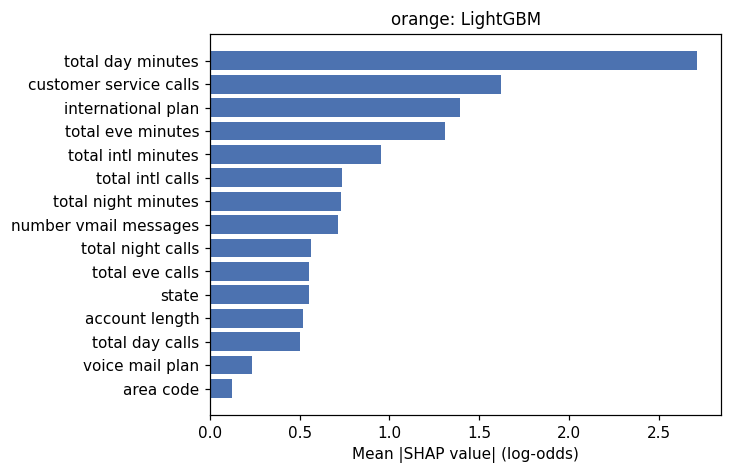

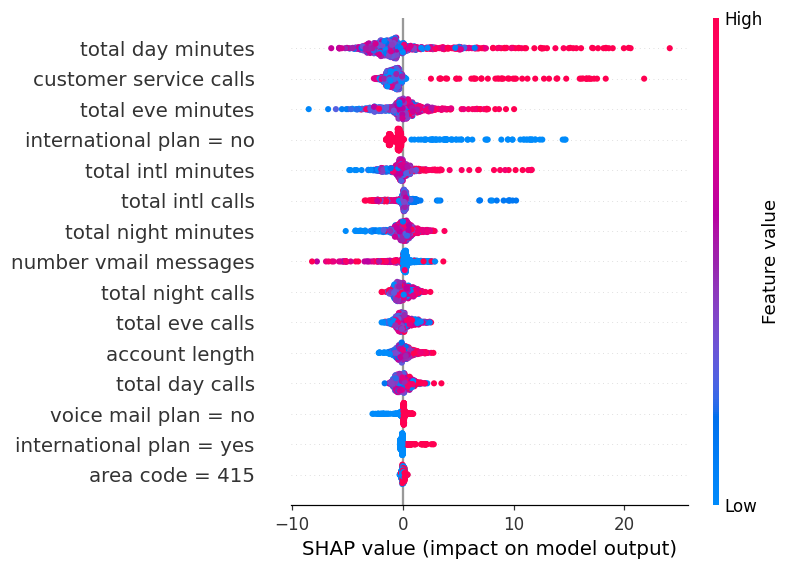


cell2cell XGBoost | base=-0.9119 | max |sum(SHAP)+base-margin| = 3.58e-06
   mean predicted prob on explained rows: 0.2952 (base prob 0.2866)
   SHAP range: [-1.04, 1.22]
Top 15 source features, cell2cell:
CurrentEquipmentDays    0.2977
MonthsInService         0.1904
PercChangeMinutes       0.1795
MonthlyMinutes          0.1551
UniqueSubs              0.0959
TotalRecurringCharge    0.0869
OverageMinutes          0.0776
CreditRating            0.0766
Minutes_per_month       0.0762
MonthlyRevenue          0.0508
ServiceArea             0.0499
PercChangeRevenues      0.0482
InboundCalls            0.0441
HandsetRefurbished      0.0439
RetentionCalls          0.0437
Top 10 encoded columns:
CurrentEquipmentDays    0.2977
MonthsInService         0.1904
PercChangeMinutes       0.1795
MonthlyMinutes          0.1551
UniqueSubs              0.0959
TotalRecurringCharge    0.0869
OverageMinutes          0.0776
Minutes_per_month       0.0762
CreditRating = 5-Low    0.0621
MonthlyRevenue          0

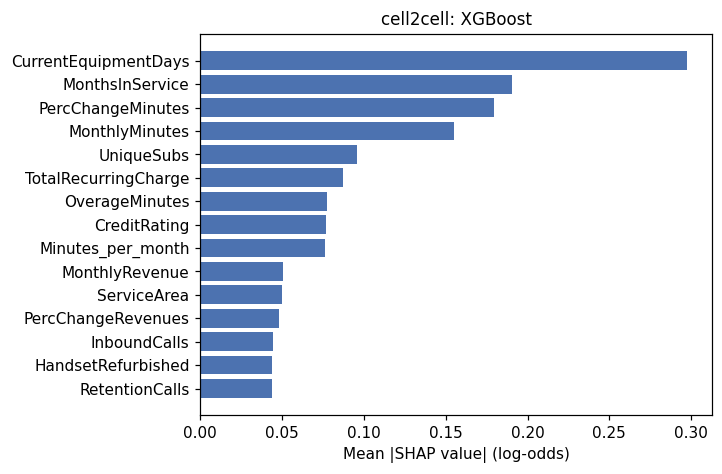

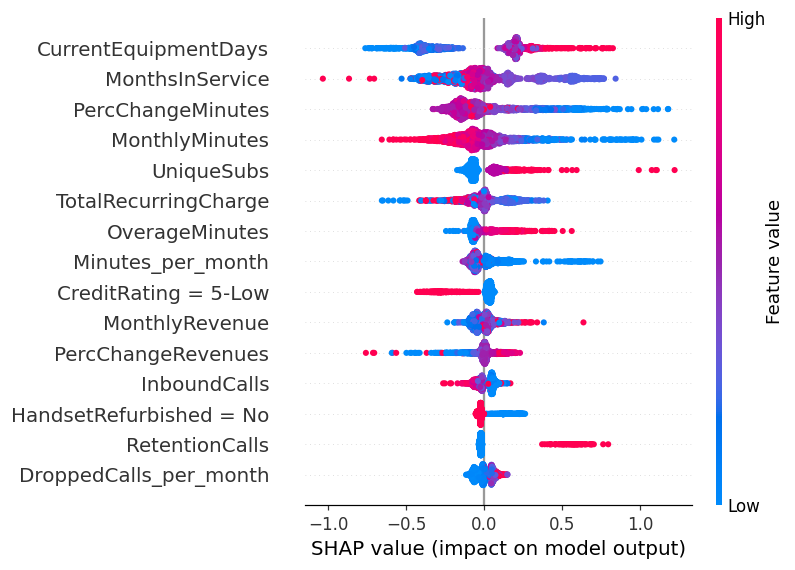


Saved corrected SHAP tables and figures.


In [40]:
# ============================================================
# STAGE 15 - SHAP additivity check, labels, and corrected Orange SHAP
# ============================================================
import os
import joblib
import warnings
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", message="X does not have valid feature names")
warnings.filterwarnings("ignore", message="LightGBM binary classifier")


def label_names(s1, s2, n_num, n_cat):
    """Имена столбцов с реальными названиями категорий."""
    all_names = s1.ct_.get_feature_names_out().tolist()
    num_names = all_names[:n_num]
    cat_names = all_names[n_num:]

    cat_cats = []
    for tname in ["cat", "sa"]:
        if tname in s1.ct_.named_transformers_:
            pipe = s1.ct_.named_transformers_[tname]
            enc = pipe.named_steps["ord"]
            for c in enc.categories_:
                cat_cats.append([str(v) for v in c])
    ohe = s2.ct_.named_transformers_["cat"]
    names, src = list(num_names), list(num_names)
    for ci, cats in enumerate(ohe.categories_):
        for v in cats:
            v = int(v)
            if 0 <= v < len(cat_cats[ci]):
                lab = cat_cats[ci][v]
            else:
                lab = "unseen"
            names.append("%s = %s" % (cat_names[ci], lab))
            src.append(cat_names[ci])
    return names, src


def get_contrib(mdl, H, name):
    """Точные вклады в лог-шансах: (n, features), base."""
    if name == "LightGBM":
        c = mdl.predict(H, pred_contrib=True)
        return c[:, :-1], float(c[0, -1])
    expl = shap.TreeExplainer(mdl)
    sv = np.asarray(expl.shap_values(H))
    if sv.ndim == 3:
        sv = sv[:, :, 1]
    return sv, float(np.ravel(expl.expected_value)[-1])


def raw_margin(mdl, H, name):
    if name == "LightGBM":
        return mdl.predict(H, raw_score=True)
    return mdl.predict(H, output_margin=True) if hasattr(
        mdl, "get_booster") is False else mdl.get_booster().predict(
        __import__("xgboost").DMatrix(H), output_margin=True)


results = {}
for ds, (mode, smote, name) in SHAP_MODEL.items():
    store = joblib.load(os.path.join(OBJ_DIR, "test_probs_%s.joblib" % ds))
    s = store[(mode, smote, name)]
    enhanced = (mode == "enhanced")
    X = SPLITS[ds]["X_train"]
    y = SPLITS[ds]["y_train"].to_numpy()
    n_num, n_cat = get_dims(ds, enhanced)
    s1 = Stage1(ds, enhanced).fit(X, y)
    Z = s1.transform(X)
    s2 = Stage2(n_num, n_cat, False).fit(Z)
    mdl = make_model(name, s["params"]).fit(s2.transform(Z), y)
    Hte = s2.transform(s1.transform(SPLITS[ds]["X_test"]))
    names, src = label_names(s1, s2, n_num, n_cat)
    assert len(names) == Hte.shape[1]

    n = SHAP_N[ds]
    if n is None:
        idx = np.arange(Hte.shape[0])
    else:
        rng = np.random.default_rng(SEED)
        idx = np.sort(rng.choice(Hte.shape[0], size=n, replace=False))
    Hs = Hte[idx]

    sv, base = get_contrib(mdl, Hs, name)
    margin = raw_margin(mdl, Hs, name)
    err = np.abs(sv.sum(axis=1) + base - margin).max()
    print("\n%s %s | base=%.4f | max |sum(SHAP)+base-margin| = %.2e"
          % (ds, name, base, err))
    p_hat = 1 / (1 + np.exp(-margin))
    print("   mean predicted prob on explained rows: %.4f "
          "(base prob %.4f)" % (p_hat.mean(), 1 / (1 + np.exp(-base))))
    print("   SHAP range: [%.2f, %.2f]" % (sv.min(), sv.max()))

    cols_by_src = {}
    for i, sc in enumerate(src):
        cols_by_src.setdefault(sc, []).append(i)
    agg = pd.Series({sc: float(np.abs(sv[:, ix].sum(axis=1)).mean())
                     for sc, ix in cols_by_src.items()}
                    ).sort_values(ascending=False)
    col_abs = pd.Series(np.abs(sv).mean(axis=0), index=names
                        ).sort_values(ascending=False)
    results[ds] = {"agg": agg, "col_abs": col_abs, "sv": sv, "Hs": Hs,
                   "names": names, "idx": idx, "base": base}

    agg.to_csv(os.path.join(TAB_DIR, "shap_source_%s.csv" % ds),
               header=["mean_abs_shap"])
    col_abs.to_csv(os.path.join(TAB_DIR, "shap_columns_%s.csv" % ds),
                   header=["mean_abs_shap"])
    print("Top 15 source features, %s:" % ds)
    print(agg.head(15).round(4).to_string())
    print("Top 10 encoded columns:")
    print(col_abs.head(10).round(4).to_string())

    top = agg.head(15)[::-1]
    fig, ax = plt.subplots(figsize=(6, 4.5))
    ax.barh(top.index, top.values, color="#4C72B0")
    ax.set_xlabel("Mean |SHAP value| (log-odds)")
    ax.set_title("%s: %s" % (ds, name))
    fig.savefig(os.path.join(FIG_DIR, "shap_bar_%s.pdf" % ds))
    fig.savefig(os.path.join(FIG_DIR, "shap_bar_%s.svg" % ds))
    plt.show()

    plt.figure()
    shap.summary_plot(sv, Hs, feature_names=names, max_display=15,
                      show=False)
    plt.gcf().set_size_inches(7, 5)
    plt.savefig(os.path.join(FIG_DIR, "shap_beeswarm_%s.pdf" % ds))
    plt.savefig(os.path.join(FIG_DIR, "shap_beeswarm_%s.svg" % ds))
    plt.show()

joblib.dump({k: {"agg": v["agg"], "col_abs": v["col_abs"]}
             for k, v in results.items()},
            os.path.join(OBJ_DIR, "shap_summary.joblib"))
print("\nSaved corrected SHAP tables and figures.")

In [41]:
# ============================================================
# STAGE 16a - Tables for the article (LaTeX + CSV)
# ============================================================
import os
import numpy as np
import pandas as pd

EOL = " \\\\"
ci = pd.read_csv(os.path.join(TAB_DIR, "main_table_ci.csv"))
pt = pd.read_csv(os.path.join(TAB_DIR, "paired_tests.csv"))
parts = []
for d in ["orange", "cell2cell"]:
    fn = "test_metrics_%s.csv" % d
    parts.append(pd.read_csv(os.path.join(TAB_DIR, fn)))
tm = pd.concat(parts, ignore_index=True)

LABEL = {"LogisticRegression": "Logistic Regression",
         "DecisionTree": "Decision Tree",
         "RandomForest": "Random Forest",
         "GradientBoosting": "Gradient Boosting",
         "XGBoost": "XGBoost", "LightGBM": "LightGBM"}
ORDER = ["LogisticRegression", "DecisionTree", "RandomForest",
         "GradientBoosting", "XGBoost", "LightGBM"]
DSN = {"orange": "Orange Telecom", "cell2cell": "Cell2Cell"}


def with_ci(v, lo, hi):
    return "{:.3f} [{:.3f}, {:.3f}]".format(v, lo, hi)


def pfmt(p):
    if p < 0.001:
        return "$<$0.001"
    return "{:.3f}".format(p)


def save_tex(name, lines):
    path = os.path.join(TAB_DIR, name)
    with open(path, "w") as f:
        f.write("\n".join(lines) + "\n")
    print("Saved", path)


def n_encoded(ds, enhanced):
    X = SPLITS[ds]["X_train"]
    y = SPLITS[ds]["y_train"].to_numpy()
    n_num, n_cat = get_dims(ds, enhanced)
    s1 = Stage1(ds, enhanced).fit(X, y)
    Z = s1.transform(X)
    s2 = Stage2(n_num, n_cat, False).fit(Z)
    return s2.transform(Z).shape[1]


raw = {"cell2cell": c2c_raw, "orange": orange_raw}
tgt = {"cell2cell": "Churn", "orange": "churn"}
rows1 = []
for ds in ["cell2cell", "orange"]:
    s = SPLITS[ds]
    r = raw[ds]
    ntr, nte = len(s["y_train"]), len(s["y_test"])
    ptr, pte = int(s["y_train"].sum()), int(s["y_test"].sum())
    nb = prep_frame(s["X_train"], ds, False).shape[1]
    ne = prep_frame(s["X_train"], ds, True).shape[1]
    rows1.append({
        "ds": ds,
        "orig": len(r),
        "cols": r.shape[1],
        "miss": int(r.drop(columns=[tgt[ds]]).isna().sum().sum()),
        "dup": int(r.duplicated().sum()),
        "feat_b": nb, "feat_e": ne,
        "enc_b": n_encoded(ds, False), "enc_e": n_encoded(ds, True),
        "ntr": ntr, "ptr": ptr, "nte": nte, "pte": pte})
t1 = {r["ds"]: r for r in rows1}
c, o = t1["cell2cell"], t1["orange"]
pd.DataFrame(rows1).to_csv(os.path.join(TAB_DIR, "table1_data.csv"),
                           index=False)

L1 = ["\\begin{tabular}{lcc}", "\\toprule",
      "Characteristic & Cell2Cell & Orange Telecom" + EOL, "\\midrule"]


def row1(label, a, b):
    L1.append("{} & {} & {}".format(label, a, b) + EOL)


row1("Labelled records (original)", "{:,}".format(c["orig"]),
     "{:,}".format(o["orig"]))
row1("Records retained", "{:,}".format(c["orig"]), "{:,}".format(o["orig"]))
row1("Columns incl. target", c["cols"], o["cols"])
row1("Missing feature values", "{:,}".format(c["miss"]), o["miss"])
row1("Duplicate rows", c["dup"], o["dup"])
row1("Identifier removed", "CustomerID", "phone number")
row1("Redundant columns removed", "none", "4 charge columns")
row1("Model inputs (basic / enhanced)",
     "{} / {}".format(c["feat_b"], c["feat_e"]),
     "{} / {}".format(o["feat_b"], o["feat_e"]))
row1("Columns after encoding (basic / enhanced)",
     "{} / {}".format(c["enc_b"], c["enc_e"]),
     "{} / {}".format(o["enc_b"], o["enc_e"]))
row1("Training records (churners)",
     "{:,} ({:,})".format(c["ntr"], c["ptr"]),
     "{:,} ({:,})".format(o["ntr"], o["ptr"]))
row1("Test records (churners)",
     "{:,} ({:,})".format(c["nte"], c["pte"]),
     "{:,} ({:,})".format(o["nte"], o["pte"]))
row1("Churn share, train / test (\\%)",
     "{:.2f} / {:.2f}".format(100 * c["ptr"] / c["ntr"],
                              100 * c["pte"] / c["nte"]),
     "{:.2f} / {:.2f}".format(100 * o["ptr"] / o["ntr"],
                              100 * o["pte"] / o["nte"]))
L1 += ["\\bottomrule", "\\end{tabular}"]
save_tex("table1_data.tex", L1)

def tmrow(ds, model, mode=None, smote=None, rule="tuned"):
    q = tm[(tm["dataset"] == ds) & (tm["model"] == model)
           & (tm["threshold_rule"] == rule)]
    if mode is not None:
        q = q[(q["mode"] == mode) & (q["smote"] == smote)]
    return q.iloc[0]


hdr = ("Model & Condition & Thr. & Acc. & Prec. & "
       "Recall [95\\% CI] & F1 [95\\% CI] & AUC & FP & FN & "
       "F1$_{0.50}$")
L2 = ["\\begin{tabular}{llccccccrrc}", "\\toprule", hdr + EOL]
main_rows = []
for ds in ["orange", "cell2cell"]:
    L2.append("\\midrule")
    L2.append("\\multicolumn{11}{l}{\\textit{%s}}" % DSN[ds] + EOL)
    d = tmrow(ds, "Dummy", rule="fixed")
    L2.append("Dummy (most frequent) & -- & -- & {:.3f} & {:.3f} & "
              "{:.3f} & {:.3f} & {:.3f} & {} & {} & {:.3f}".format(
                  d["acc"], d["prec"], d["rec"], d["f1"], d["auc"],
                  int(d["fp"]), int(d["fn"]), d["f1"]) + EOL)
    for m in ORDER:
        q = ci[(ci["dataset"] == ds) & (ci["model"] == m)].iloc[0]
        mode, sm = q["mode"], bool(q["smote"])
        cond = mode.capitalize() + (", SMOTE-NC" if sm else "")
        t = tmrow(ds, m, mode, sm, "tuned")
        h = tmrow(ds, m, mode, sm, "0.50")
        L2.append("{} & {} & {:.2f} & {:.3f} & {:.3f} & {} & {} & "
                  "{:.3f} & {} & {} & {:.3f}".format(
                      LABEL[m], cond, q["thr"], q["acc"], q["prec"],
                      with_ci(q["rec"], q["rec_lo"], q["rec_hi"]),
                      with_ci(q["f1"], q["f1_lo"], q["f1_hi"]),
                      q["auc"], int(t["fp"]), int(t["fn"]), h["f1"]) + EOL)
        main_rows.append({"dataset": ds, "model": m, "condition": cond,
                          "thr": q["thr"], "acc": q["acc"],
                          "prec": q["prec"], "rec": q["rec"],
                          "rec_lo": q["rec_lo"], "rec_hi": q["rec_hi"],
                          "f1": q["f1"], "f1_lo": q["f1_lo"],
                          "f1_hi": q["f1_hi"], "auc": q["auc"],
                          "auc_lo": q["auc_lo"], "auc_hi": q["auc_hi"],
                          "fp": int(t["fp"]), "fn": int(t["fn"]),
                          "f1_at_0.50": h["f1"]})
    a = tmrow(ds, "PredictAllChurn", rule="fixed")
    L2.append("Predict all churn (reference) & -- & -- & {:.3f} & {:.3f} "
              "& {:.3f} & {:.3f} & {:.3f} & {} & {} & {:.3f}".format(
                  a["acc"], a["prec"], a["rec"], a["f1"], a["auc"],
                  int(a["fp"]), int(a["fn"]), a["f1"]) + EOL)
L2 += ["\\bottomrule", "\\end{tabular}"]
save_tex("table2_main.tex", L2)
pd.DataFrame(main_rows).to_csv(os.path.join(TAB_DIR, "table2_main.csv"),
                               index=False)

blocks = [("orange", "RQ1_basic_vs_enhanced"),
          ("orange", "RQ2_plain_vs_smote"),
          ("cell2cell", "RQ1_basic_vs_enhanced"),
          ("cell2cell", "RQ2_plain_vs_smote")]
L3 = ["\\begin{tabular}{lcccccccc}", "\\toprule",
      " & \\multicolumn{4}{c}{Orange Telecom} & "
      "\\multicolumn{4}{c}{Cell2Cell}" + EOL,
      "\\cmidrule(lr){2-5}\\cmidrule(lr){6-9}",
      " & \\multicolumn{2}{c}{RQ1} & \\multicolumn{2}{c}{RQ2} & "
      "\\multicolumn{2}{c}{RQ1} & \\multicolumn{2}{c}{RQ2}" + EOL,
      "\\cmidrule(lr){2-3}\\cmidrule(lr){4-5}"
      "\\cmidrule(lr){6-7}\\cmidrule(lr){8-9}",
      "Model & $\\Delta$F1 [95\\% CI] & $p_{\\mathrm{Holm}}$ & "
      "$\\Delta$F1 [95\\% CI] & $p_{\\mathrm{Holm}}$ & "
      "$\\Delta$F1 [95\\% CI] & $p_{\\mathrm{Holm}}$ & "
      "$\\Delta$F1 [95\\% CI] & $p_{\\mathrm{Holm}}$" + EOL,
      "\\midrule"]
for m in ORDER:
    cells = [LABEL[m]]
    for ds, fam in blocks:
        r = pt[(pt["dataset"] == ds) & (pt["family"] == fam)
               & (pt["model"] == m)].iloc[0]
        cells.append("{:+.3f} [{:+.3f}, {:+.3f}]".format(
            r["diff_B_minus_A"], r["ci_lo"], r["ci_hi"]))
        ptxt = pfmt(r["p_holm"])
        if r["p_holm"] < ALPHA:
            ptxt = "\\textbf{%s}" % ptxt
        cells.append(ptxt)
    L3.append(" & ".join(cells) + EOL)
L3 += ["\\bottomrule", "\\end{tabular}"]
save_tex("table3_paired.tex", L3)

print("\n--- Table 1 ---")
print("\n".join(L1))
print("\n--- Table 2 (first 12 lines) ---")
print("\n".join(L2[:12]))
print("\n--- Table 3 ---")
print("\n".join(L3))

Saved /content/drive/MyDrive/churn_assignment3/tables/table1_data.tex
Saved /content/drive/MyDrive/churn_assignment3/tables/table2_main.tex
Saved /content/drive/MyDrive/churn_assignment3/tables/table3_paired.tex

--- Table 1 ---
\begin{tabular}{lcc}
\toprule
Characteristic & Cell2Cell & Orange Telecom \\
\midrule
Labelled records (original) & 51,047 & 3,333 \\
Records retained & 51,047 & 3,333 \\
Columns incl. target & 58 & 21 \\
Missing feature values & 3,515 & 0 \\
Duplicate rows & 0 & 0 \\
Identifier removed & CustomerID & phone number \\
Redundant columns removed & none & 4 charge columns \\
Model inputs (basic / enhanced) & 56 / 61 & 15 / 18 \\
Columns after encoding (basic / enhanced) & 155 / 160 & 69 / 72 \\
Training records (churners) & 40,837 (11,769) & 2,666 (386) \\
Test records (churners) & 10,210 (2,942) & 667 (97) \\
Churn share, train / test (\%) & 28.82 / 28.81 & 14.48 / 14.54 \\
\bottomrule
\end{tabular}

--- Table 2 (first 12 lines) ---
\begin{tabular}{llccccccrrc}
\t

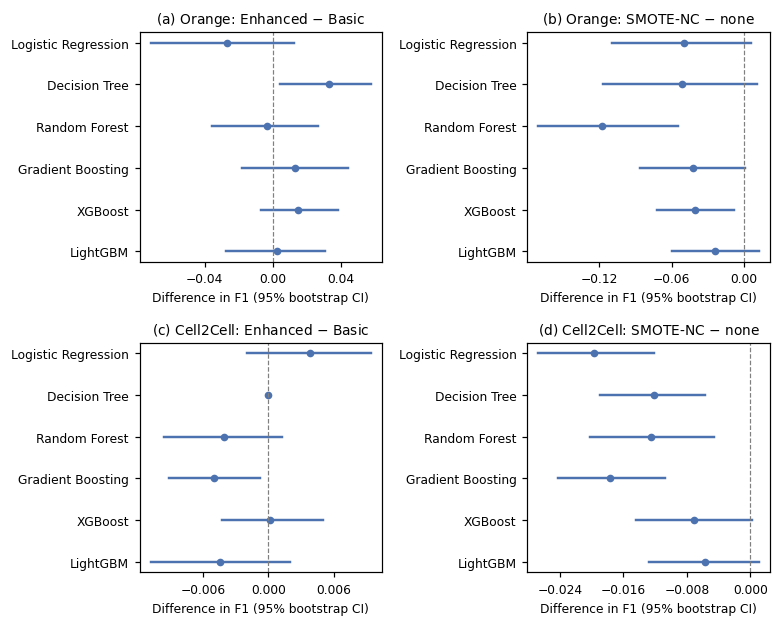

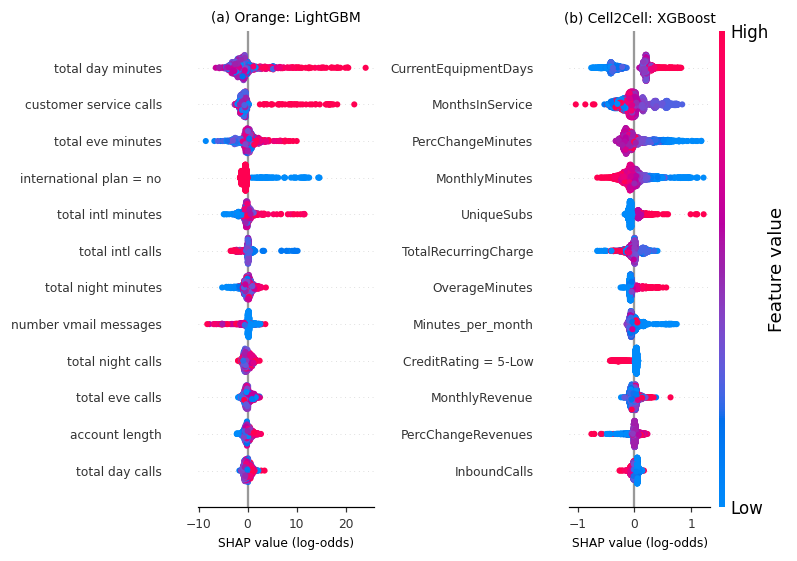

Saved fixed figures.


In [43]:
# ============================================================
# STAGE 16b - Figure fixes (tick density, font sizes)
# ============================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import shap

pt = pd.read_csv(os.path.join(TAB_DIR, "paired_tests.csv"))
LABEL = {"LogisticRegression": "Logistic Regression",
         "DecisionTree": "Decision Tree",
         "RandomForest": "Random Forest",
         "GradientBoosting": "Gradient Boosting",
         "XGBoost": "XGBoost", "LightGBM": "LightGBM"}
ORDER = ["LogisticRegression", "DecisionTree", "RandomForest",
         "GradientBoosting", "XGBoost", "LightGBM"]

panels = [("orange", "RQ1_basic_vs_enhanced", "(a) Orange: Enhanced $-$ Basic"),
          ("orange", "RQ2_plain_vs_smote", "(b) Orange: SMOTE-NC $-$ none"),
          ("cell2cell", "RQ1_basic_vs_enhanced", "(c) Cell2Cell: Enhanced $-$ Basic"),
          ("cell2cell", "RQ2_plain_vs_smote", "(d) Cell2Cell: SMOTE-NC $-$ none")]
fig, axes = plt.subplots(2, 2, figsize=(7.2, 5.8))
for ax, (ds, fam, title) in zip(axes.ravel(), panels):
    sub = pt[(pt["dataset"] == ds) & (pt["family"] == fam)]
    sub = sub.set_index("model").loc[ORDER]
    ypos = np.arange(len(ORDER))[::-1]
    for y, (m, r) in zip(ypos, sub.iterrows()):
        ax.plot([r["ci_lo"], r["ci_hi"]], [y, y], color="#4C72B0", lw=1.6)
        ax.plot(r["diff_B_minus_A"], y, "o", color="#4C72B0", ms=4)
    ax.axvline(0, color="grey", lw=0.8, ls="--")
    ax.set_yticks(ypos)
    ax.set_yticklabels([LABEL[m] for m in ORDER], fontsize=8)
    ax.set_title(title, fontsize=9)
    ax.set_xlabel("Difference in F1 (95% bootstrap CI)", fontsize=8)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
    ax.tick_params(axis="x", labelsize=8)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "fig_forest_deltaF1.pdf"))
fig.savefig(os.path.join(FIG_DIR, "fig_forest_deltaF1.svg"))
plt.show()

fig2, axs = plt.subplots(1, 2, figsize=(7.4, 5.2))
for ax, ds, ttl in zip(axs, ["orange", "cell2cell"],
                       ["(a) Orange: LightGBM", "(b) Cell2Cell: XGBoost"]):
    r = results[ds]
    plt.sca(ax)
    shap.summary_plot(r["sv"], r["Hs"], feature_names=r["names"],
                      max_display=12, show=False, plot_size=None,
                      color_bar=(ds == "cell2cell"))
    ax.set_title(ttl, fontsize=9)
    ax.set_xlabel("SHAP value (log-odds)", fontsize=8)
    ax.tick_params(axis="y", labelsize=8)
    ax.tick_params(axis="x", labelsize=8)
fig2.tight_layout()
fig2.savefig(os.path.join(FIG_DIR, "fig_shap_panel.pdf"))
fig2.savefig(os.path.join(FIG_DIR, "fig_shap_panel.svg"))
plt.show()
print("Saved fixed figures.")

In [44]:
# ============================================================
# STAGE 17 - Reproducibility summary and repository files
# ============================================================
import os
import json
import glob
import joblib
import platform
import importlib.metadata as md
import numpy as np
import pandas as pd

tune_sec = {"orange": 0.0, "cell2cell": 0.0}
for f in glob.glob(os.path.join(OBJ_DIR, "tune_*.joblib")):
    r = joblib.load(f)
    tune_sec[r["dataset"]] += float(r["seconds"])

fit_sec = {}
for ds in ["orange", "cell2cell"]:
    st = joblib.load(os.path.join(OBJ_DIR, "test_probs_%s.joblib" % ds))
    fit_sec[ds] = float(sum(v["fit_sec"] for v in st.values()))

timing = pd.DataFrame([
    {"dataset": ds,
     "tuning_min": tune_sec[ds] / 60,
     "final_fit_min": fit_sec[ds] / 60,
     "total_min": (tune_sec[ds] + fit_sec[ds]) / 60}
    for ds in ["orange", "cell2cell"]])
timing.loc[len(timing)] = ["all", timing["tuning_min"].sum(),
                           timing["final_fit_min"].sum(),
                           timing["total_min"].sum()]
timing.to_csv(os.path.join(TAB_DIR, "runtime_summary.csv"), index=False)
print("MEASURED COMPUTE TIME (sum of saved timings, minutes)")
print(timing.round(1).to_string(index=False))

pkgs = ["numpy", "pandas", "scipy", "scikit-learn", "imbalanced-learn",
        "xgboost", "lightgbm", "shap", "statsmodels", "matplotlib",
        "joblib"]
versions = {}
for p in pkgs:
    try:
        versions[p] = md.version(p)
    except Exception:
        versions[p] = "n/a"
env = {"python": platform.python_version(),
       "platform": platform.platform(),
       "cpu_cores": os.cpu_count(),
       "gpu": "none"}

req_path = os.path.join(BASE_DIR, "requirements.txt")
with open(req_path, "w") as f:
    for p in pkgs:
        if versions[p] != "n/a":
            f.write("%s==%s\n" % (p, versions[p]))
with open(os.path.join(OBJ_DIR, "environment.json"), "w") as f:
    json.dump({"env": env, "versions": versions}, f, indent=2)
print("\nSaved requirements.txt and environment.json")
print(env)

tabs = sorted(os.listdir(TAB_DIR))
figs = sorted(os.listdir(FIG_DIR))
print("\nTables:", len(tabs), "| Figures:", len(figs))

readme = []
readme.append("# Telecom churn prediction: Assignment 3 (Results)")
readme.append("")
readme.append("Experiments for the article on customer churn prediction "
              "with Cell2Cell and Orange Telecom data.")
readme.append("")
readme.append("## Data")
readme.append("Datasets are not redistributed. Download them from Kaggle:")
readme.append("- Cell2Cell: https://www.kaggle.com/datasets/jpacse/"
              "datasets-for-churn-telecom")
readme.append("- Orange Telecom: https://www.kaggle.com/datasets/"
              "becksddf/churn-in-telecoms-dataset")
readme.append("Place `cell2celltrain.csv.zip` and "
              "`bigml_59c28831336c6604c800002a.csv` in `data/`.")
readme.append("The Cell2Cell archive used here contained only the labelled "
              "file; no unlabelled holdout file was present.")
readme.append("")
readme.append("## Settings")
readme.append("Seed %d; stratified %d/%d split; %d-fold CV; %d bootstrap "
              "resamples; alpha %.2f." % (
                  SEED, int(100 * (1 - TEST_SIZE)), int(100 * TEST_SIZE),
                  N_SPLITS, N_BOOT, ALPHA))
readme.append("Ensemble search budget: n_iter=10 (Orange), n_iter=6 "
              "(Cell2Cell). Logistic Regression and Decision Tree use full "
              "grids. Configuration score: best F1 over the threshold grid "
              "on pooled out-of-fold predictions.")
readme.append("")
readme.append("## Reproduce")
readme.append("1. Install `requirements.txt` (Python %s)." % env["python"])
readme.append("2. Open the notebook in Google Colab (CPU runtime) and run "
              "the stages in order.")
readme.append("3. Tuning results are cached in `objects/`; delete them to "
              "recompute.")
readme.append("")
readme.append("## Environment used")
readme.append("Python %s, %s, %s CPU cores, no GPU." % (
    env["python"], env["platform"], env["cpu_cores"]))
readme.append("")
readme.append("## Outputs")
readme.append("`tables/` (CSV and LaTeX), `figures/` (PDF and SVG).")
readme.append("")
readme.append("Repository URL: TBD")
with open(os.path.join(BASE_DIR, "README.md"), "w") as f:
    f.write("\n".join(readme) + "\n")
print("Saved README.md")
print("\nTables:", tabs)
print("Figures:", figs)

MEASURED COMPUTE TIME (sum of saved timings, minutes)
  dataset  tuning_min  final_fit_min  total_min
   orange        17.5            0.7       18.2
cell2cell       269.2           26.8      296.0
      all       286.7           27.5      314.2

Saved requirements.txt and environment.json
{'python': '3.13.16', 'platform': 'Linux-6.6.122+-x86_64-with-glibc2.39', 'cpu_cores': 2, 'gpu': 'none'}

Tables: 24 | Figures: 12
Saved README.md

Tables: ['confusion_selected.csv', 'error_profile.csv', 'main_table_ci.csv', 'paired_tests.csv', 'rq2_recall_precision.csv', 'runtime_summary.csv', 'selection.csv', 'shap_columns_cell2cell.csv', 'shap_columns_orange.csv', 'shap_source_cell2cell.csv', 'shap_source_orange.csv', 'split_summary.csv', 'table1_data.csv', 'table1_data.tex', 'table2_main.csv', 'table2_main.tex', 'table3_paired.tex', 'test_metrics_cell2cell.csv', 'test_metrics_orange.csv', 'threshold_sensitivity.csv', 'tuning_all_oof.csv', 'tuning_c2c_part1.csv', 'tuning_c2c_part2.csv', 'tuning_or